# Titanic: Exploratory Data Analysis (Week 3 tutorial, worked example)

**What this notebook covers:** a complete exploratory data analysis (EDA) of the Titanic passenger list (`train.csv`, 891 passengers, 12 columns). It follows the steps from the lecture slide "6 steps to do your EDA": load the data, find and handle missing values, turn numbers into categories, test which variables are related (chi-squared tests), look for outliers, transform and normalise skewed columns, and build new features such as a passenger's title, "rich" (first class) and "military age". It then relates these features to survival with four methods: logistic regression, association rules (Apriori), gradient boosting and random forests.

**How to run it:** this notebook runs in your browser, so there is nothing to install. Click a code cell and press **Shift + Enter** to run it and move to the next one, or use **Run → Run All Cells**. Run the cells in order, because later cells use columns created earlier. The first code cell installs `seaborn`, `missingno` and `mlxtend` into the browser, which takes a few seconds the first time. The heat maps and the random-forest cells take a few seconds each.

**What to expect:** 177 passengers have no age, 687 no cabin and 2 no port of embarkation. Age is related to sex, class and the number of siblings/spouses on board (chi-squared p < 0.05), but not to fare or number of parents/children. Being female is the strongest single predictor of survival: about 78% accuracy with logistic regression and 76% with gradient boosting and random forests on the same test set.

**Read it critically:** this is a worked example written in the style of a student project. Some cells contain mistakes. The notes marked ⚠️ explain what goes wrong and why; spotting problems like these is part of EDA.

`train.csv` is in the same folder as this notebook, so pandas finds it by name.

## 1. Load the libraries and the data

The first cell imports everything the notebook uses, grouped by task, and reads `train.csv` into a DataFrame called `trainingData`. Each row is one passenger; `Survived` is 1 if the passenger survived and 0 if not. The `warnings` lines hide a harmless technical warning from the browser's Python kernel; importing `mlxtend` would otherwise make it appear under every cell.

In [ ]:
%pip install seaborn missingno mlxtend
# Why: load every library the notebook uses and read the data. The %pip line above installs seaborn, missingno and mlxtend into the browser.
# Output: only pip messages; the first run takes a few seconds. Keep %pip as the first line of the cell.
# Note: StratifiedKFold, GridSearchCV, SVC, VotingClassifier, KNeighborsClassifier and DecisionTreeClassifier are imported but not used.
# For the data processing and maths
import matplotlib.pyplot as matplot
import numpy as np
import pandas as pd
import seaborn
import missingno as misnum

# For the Chi-squared tests
from scipy import stats
from scipy.stats import chi2_contingency # This is for the various statistical tests

# For the imputation
from sklearn.experimental import enable_iterative_imputer # must come before importing IterativeImputer (an experimental feature); used for 'Age'
from sklearn.impute import IterativeImputer
from sklearn.impute import SimpleImputer # For imputing the 'embarked' data
from sklearn import preprocessing # contains MinMaxScaler, used to normalise (rescale) the data

# For the Apriori algorithm
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning, module='pyodide_kernel')  # hide a harmless browser-kernel warning that mlxtend switches on

# For gradient boosting (replaces CatBoost, which does not run in the browser)
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# For splitting the data and for the models (logistic regression, random forest)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier as rfc
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics
from sklearn.metrics import accuracy_score

# For the classification report and the confusion matrix (random-forest section)
from sklearn.metrics import classification_report as cr
from sklearn.metrics import confusion_matrix as cm
from sklearn.tree import DecisionTreeClassifier


trainingData = pd.read_csv('train.csv')  # 891 rows (passengers) and 12 columns


## 2. Pre-processing

The next cells follow the lecture's EDA steps: identify missing data, organise the data into useful formats, deal with the missing values, and look for noise and outliers.

In [2]:
# (Section marker only: this cell has no code and prints nothing.)
#----START OF PRE-PROCESSING

### Identify missing data

`isnull().any()` finds the columns that contain at least one missing value; the first printout counts them. The cell then prints, column by column, the rows where that column is missing (the long list under *Missing Age* shows the 177 passengers without an age).

In [3]:
# Why: find which columns have missing values and look at those rows; this is the first EDA step.
# Output: Age 177, Cabin 687 and Embarked 2 missing, then one block per column ('Empty DataFrame' means nothing is missing there).
# Note: the Name check appears twice (again as 'Missing Names' at the end).
# Check to see if there are any null data
null_columns=trainingData.columns[trainingData.isnull().any()]  # names of the columns with at least one missing value
print("All missing data")
print(trainingData[null_columns].isnull().sum())

# PassengerId
print("Missing PassengerId")
print(trainingData[trainingData["PassengerId"].isnull()][null_columns])

# Pclass
print("Missing Pclass")
print(trainingData[trainingData["Pclass"].isnull()][null_columns])

# Name
print("Missing Name")
print(trainingData[trainingData["Name"].isnull()][null_columns])

# Sex
print("Missing Sex")
print(trainingData[trainingData["Sex"].isnull()][null_columns])

# Age
print("Missing Age")
print(trainingData[trainingData["Age"].isnull()][null_columns])

# SibSp
print("Missing SibSp")
print(trainingData[trainingData["SibSp"].isnull()][null_columns])

# Parch
print("Missing Parch")
print(trainingData[trainingData["Parch"].isnull()][null_columns])

# Ticket
print("Missing Ticket")
print(trainingData[trainingData["Ticket"].isnull()][null_columns])

# Fare
print("Missing Fare")
print(trainingData[trainingData["Fare"].isnull()][null_columns])

# Cabin
print("Missing Cabin")
print(trainingData[trainingData["Cabin"].isnull()][null_columns])

# Embarked
print("Missing Embarked")
print(trainingData[trainingData["Embarked"].isnull()][null_columns])

# Name
print("Missing Names")
print(trainingData[trainingData["Name"].isnull()][null_columns])

All missing data
Age         177
Cabin       687
Embarked      2
dtype: int64
Missing PassengerId
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Pclass
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Name
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Sex
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Age
     Age Cabin Embarked
5    NaN   NaN        Q
17   NaN   NaN        S
19   NaN   NaN        C
26   NaN   NaN        C
28   NaN   NaN        Q
..   ...   ...      ...
859  NaN   NaN        C
863  NaN   NaN        S
868  NaN   NaN        S
878  NaN   NaN        S
888  NaN   NaN        S

[177 rows x 3 columns]
Missing SibSp
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Parch
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Ticket
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Fare
Empty DataFrame
Columns: [Age, Cabin, Embarked]
Index: []
Missing Cabin
    

### Visualise the missing data

`missingno.matrix` draws one row of pixels per passenger: dark means a value is present, white means it is missing. The first plot is in file order; the next three sort the rows by `Cabin`, `Age` and `Embarked`, so all missing values of that column are grouped together and you can see whether other columns are missing in the same rows.

<details><summary>What do you notice?</summary>

`Cabin` is missing for most passengers (687 of 891), `Age` for about one in five, and `Embarked` for only two. Sorting by `Cabin` shows that most passengers without an age also have no cabin (158 of the 177), so the missing values are not completely at random.
</details>

<Axes: >

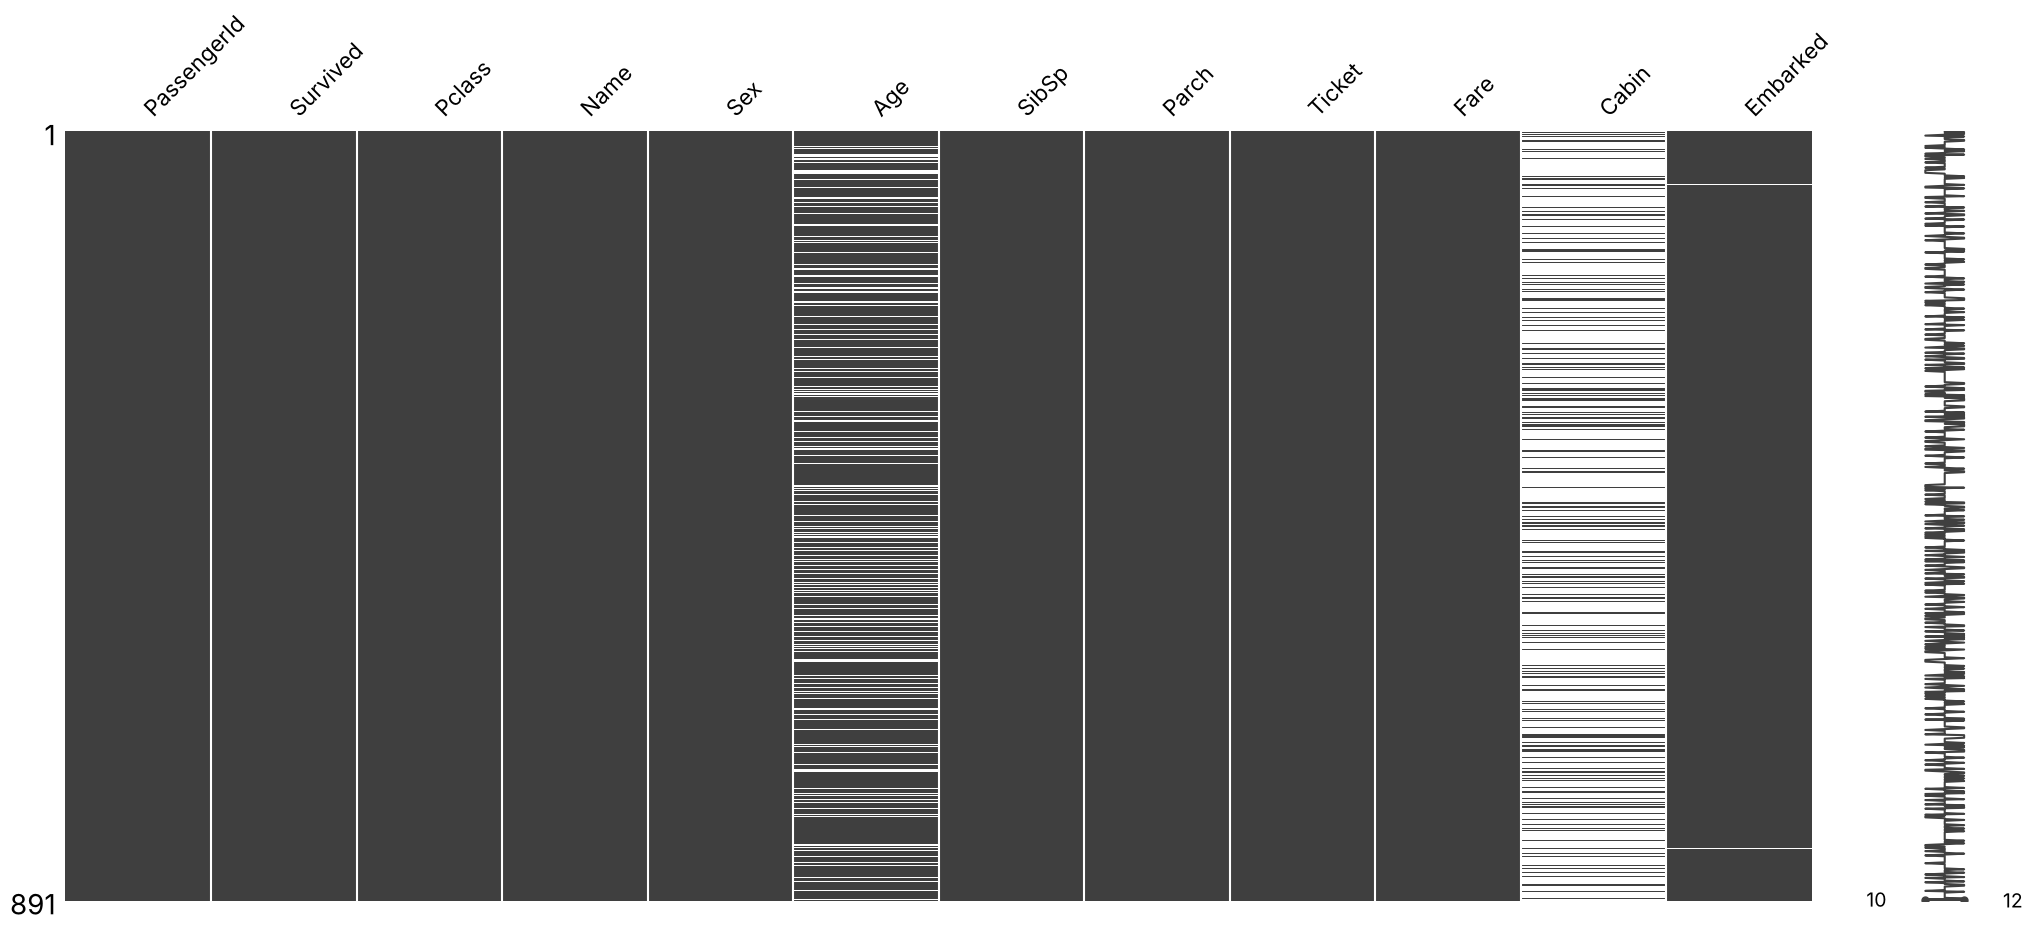

In [4]:
# Why: see the missing values as a picture instead of numbers.
# Output: one bar per column, white gaps are missing values; the line on the right shows how complete each row is.
# The text `<Axes: >` above the picture can be ignored.
# Visualise all of the missing data using the missingno Python library
misnum.matrix(trainingData)

<Axes: >

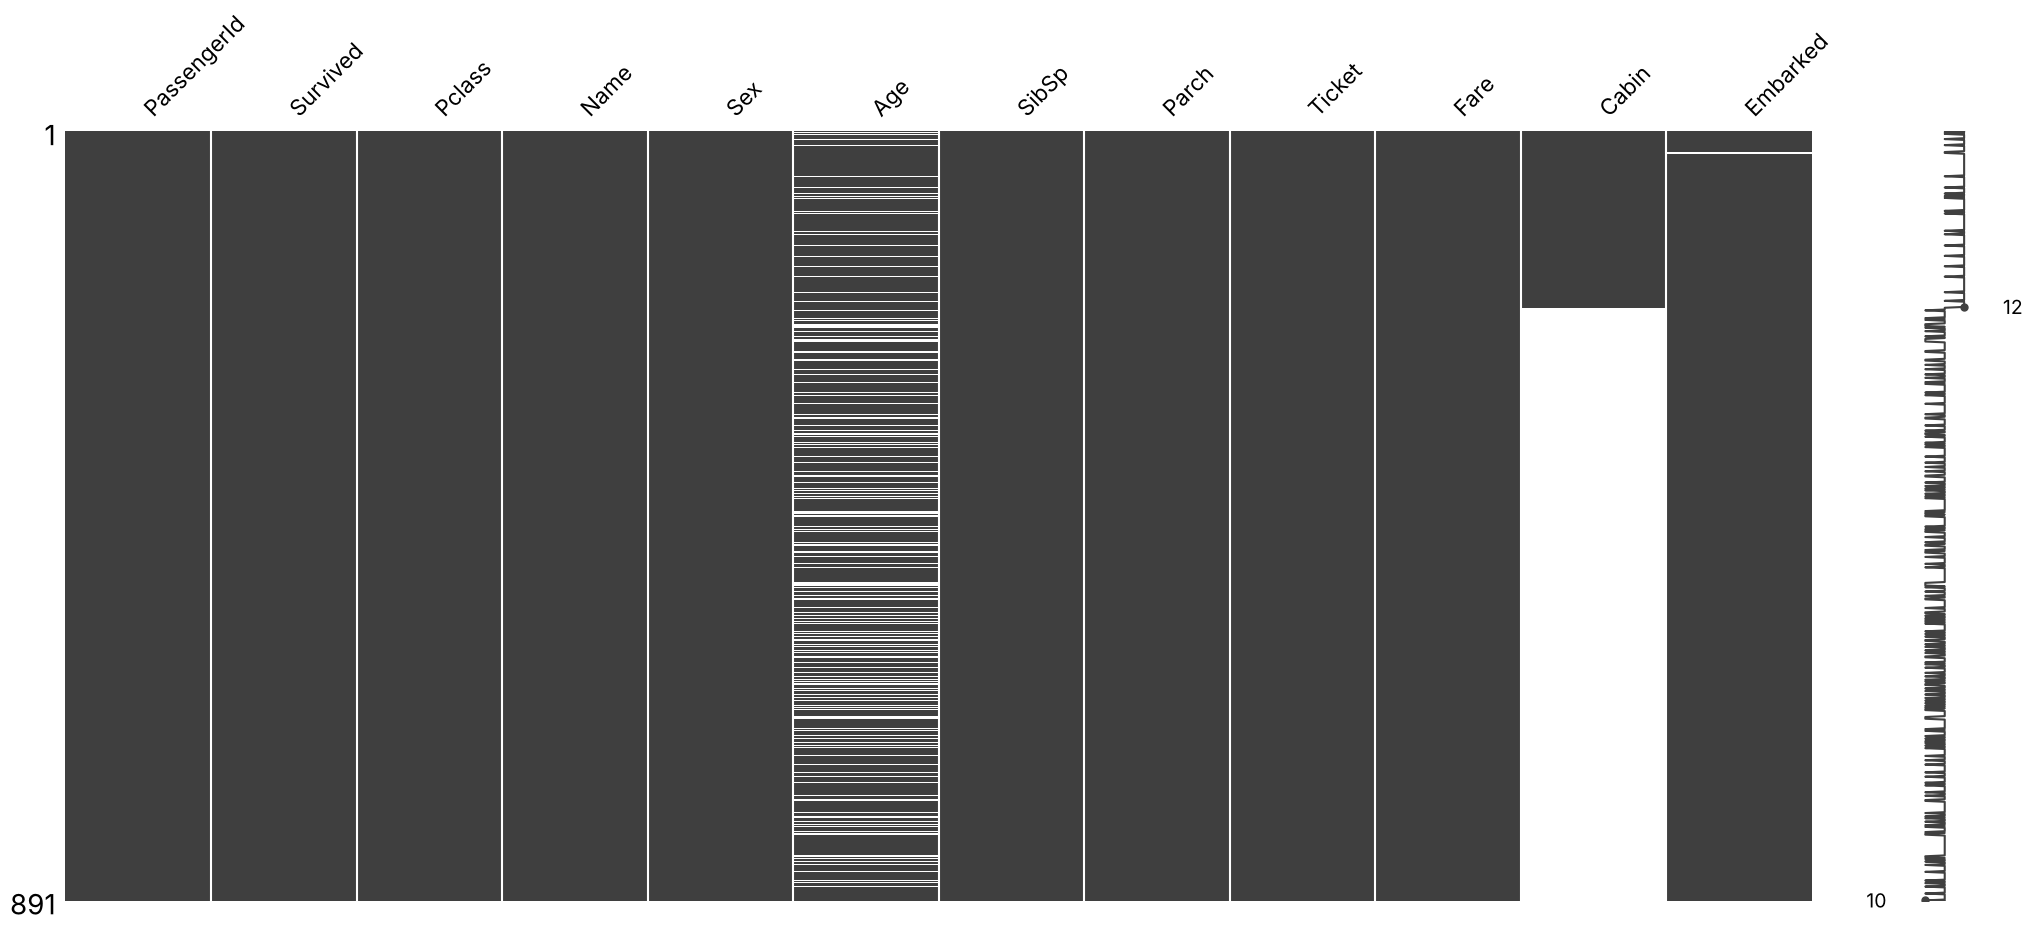

In [5]:
# Output: the same picture with the rows sorted by Cabin, so the missing cabins are grouped at the bottom.
# Sort the above visualisation by Cabin
misnum.matrix(trainingData.sort_values('Cabin'))

<Axes: >

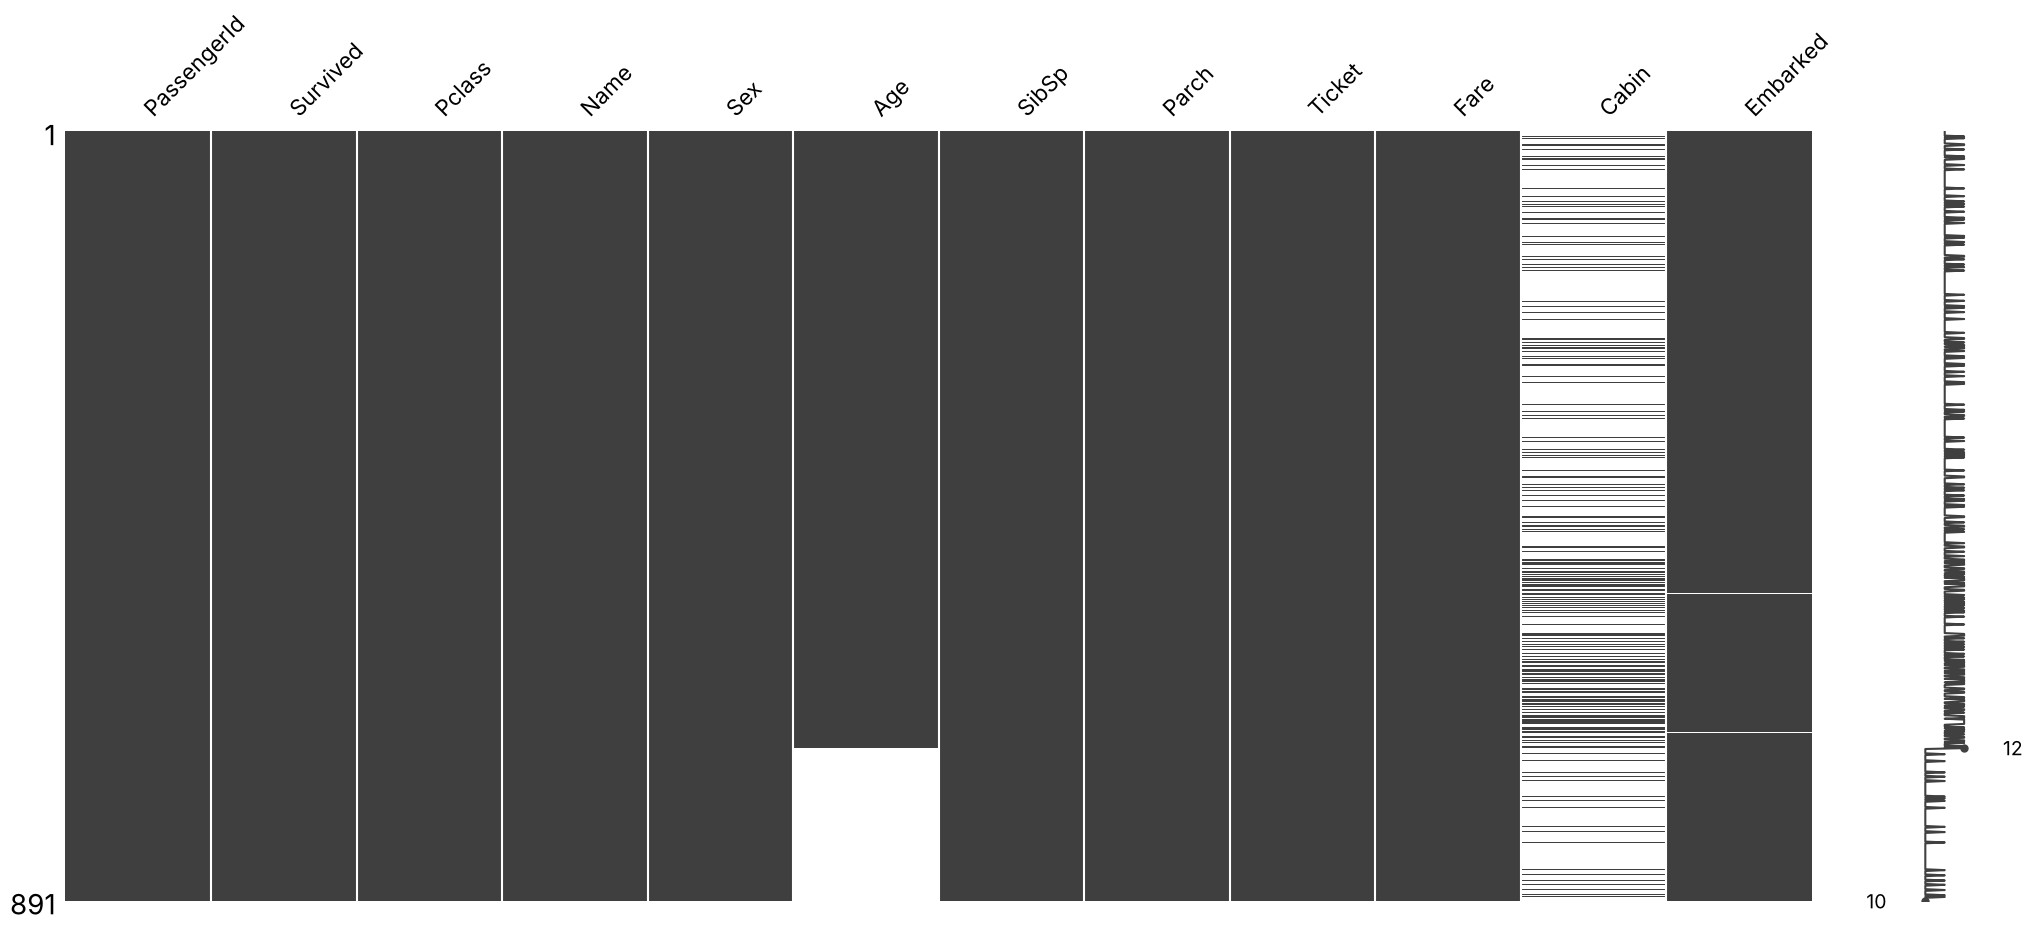

In [6]:
# Output: the same picture sorted by Age; compare where the missing ages and the missing cabins fall.
# Sort the above visualisation by Age
misnum.matrix(trainingData.sort_values('Age'))

<Axes: >

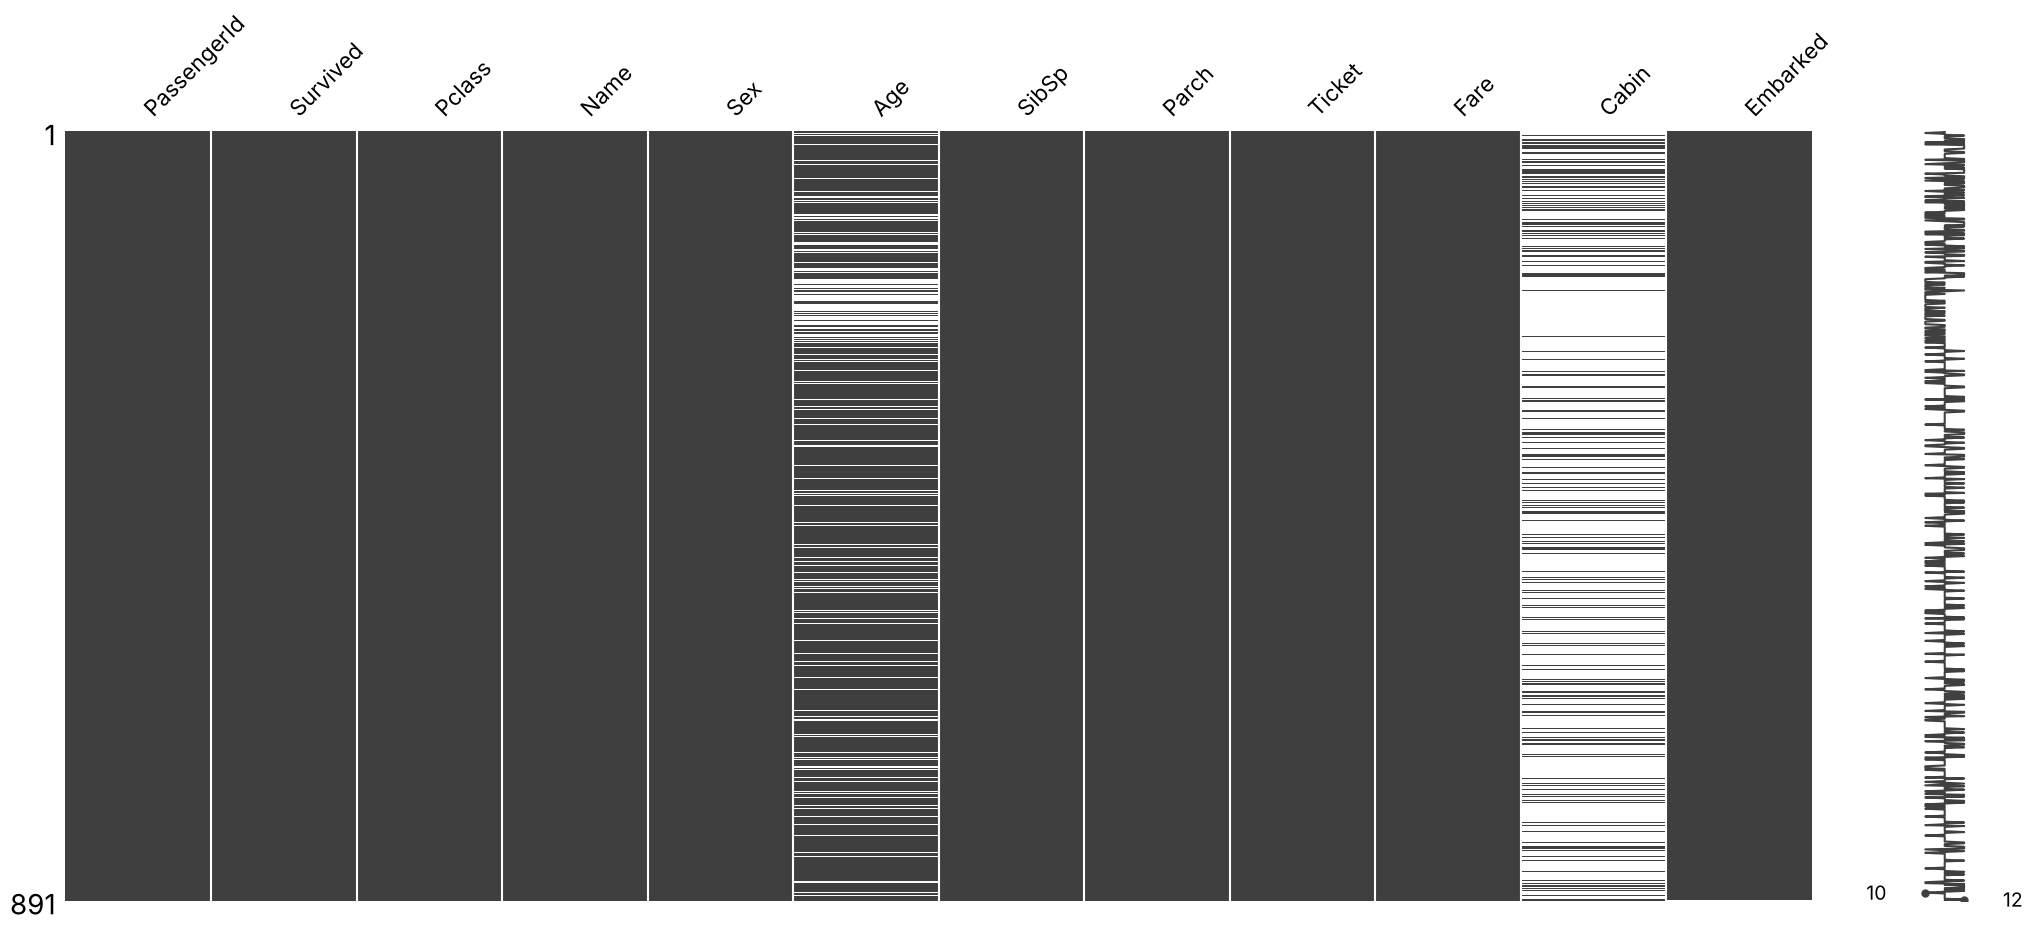

In [7]:
# Output: the same picture sorted by Embarked; its two missing values are the two white lines at the bottom.
# Sort the above visualisation by Embarked
misnum.matrix(trainingData.sort_values('Embarked'))

A *unit non-response* is a row where every value is missing. The empty table shows there are none, so no row has to be removed for that reason.

In [8]:
# Why: rows where every value is missing would be useless and should be removed.
# What: isna().all(axis=1) is True only when all values in a row are missing.
# Output: an empty table (only the column names): there are no such rows.
# Check to see if there are any 'unit non-responses' (entire rows that are empty)
trainingData[trainingData.isna().all(axis=1)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


### Turn numeric columns into categories

The chi-squared tests below need categories, not raw numbers, so these cells cut `Age`, `SibSp` (siblings/spouses on board), `Parch` (parents/children on board), `Ticket` and `Fare` into groups with `pd.cut` and store them in new `cat_…` columns. With `bins=[0,14,64,150]` and `right=True`, the age groups are 0–14 (`Low`), over 14 up to 64 (`Middle`) and over 64 (`High`).

⚠️ `cat_age` is made **before** the missing ages are filled in (section "Impute the missing ages" below), so the 177 passengers without an age have no age group; they count as "not in this group" in every age column used later.

In [9]:
# Why: the chi-squared tests below need age groups, not exact ages.
# What: pd.cut puts each age into a bin: 0 to 14 -> 'Low', over 14 up to 64 -> 'Middle', over 64 -> 'High'.
# Output: none. The 177 missing ages have no group, because they are filled in only later.
# Create a categorical version of the numeric data columns
# Categorise the age data into a 'cat_age' column
trainingData['cat_age'] = trainingData['Age']
trainingData['cat_age'] = pd.cut(trainingData['cat_age'], bins = [0,14,64,150], include_lowest = True, right = True, labels=['Low','Middle','High'])

In [10]:
# What: SibSp 0-2 -> 'Low', 3-5 -> 'Middle', 6-8 -> 'High'.
# Output: none.
# Categorise the 'SibSp' data into a 'cat_SibSp' column
trainingData['cat_SibSp'] = trainingData['SibSp']
trainingData['cat_SibSp'] = pd.cut(trainingData['cat_SibSp'], bins = [0,2,5,8], include_lowest = True, right = True, labels=['Low','Middle','High'])

In [11]:
# Output: none.
# Categorise the 'Parch' data into a 'cat_Parch' column
trainingData['cat_Parch'] = trainingData['Parch']
# Parch 0-2 -> 'Low', 3-4 -> 'Middle', 5-6 -> 'High'
trainingData['cat_Parch'] = pd.cut(trainingData['cat_Parch'], bins = [0,2,4,6], include_lowest = True, right = True, labels=['Low','Middle','High'])

`Ticket` values are text such as `A/5 21171` or `113803`. This cell labels each ticket `letter` or `noLetter`, depending on whether it contains a letter, and stores the label in `cat_ticket`. (It also copies `Ticket` into a second column `cat_Ticket`, with a capital T, which is not used again.)

In [12]:
# Why: label each ticket 'letter' or 'noLetter', to test later whether the ticket type is related to age.
# What: items() gives (row number, ticket) pairs, and str(item) turns a pair into text such as "(0, 'A/5 21171')".
# Output: none. Only the new column cat_ticket is used later; the lists are side results.
# Note: letter_ordinal_list and only_number_ordinal_list hold row numbers, not ticket numbers.
# Categorise 'ticket' into 'with letters' and 'without letters'
trainingData['cat_Ticket'] =  trainingData['Ticket']
has_letter = []
no_letter = []
letter_ordinal_list = []
only_number_ordinal_list = []
cat_list = []
# Iterate through the array and check if it contains a letter
for item in trainingData['Ticket'].items():
    string = str(item)
    if any(a.isalpha() for a in string):
        # Split the text at the comma: row number before it, ticket after it
        formatted_text = string.partition(",")[0]
        formatted_ticket = string.partition(",")[2]
        has_letter.append(formatted_ticket)
        category = 'letter'
        cat_list.append(category)
        final_formtatted_text = formatted_text[1:]
        letter_ordinal_list.append(final_formtatted_text)
    else:
        # Split the text at the comma: row number before it, ticket after it
        number_formatted_text = string.partition(",")[0]
        formatted_number_ticket = string.partition(",")[2]
        no_letter.append(formatted_ticket)
        category = 'noLetter'
        cat_list.append(category)
        number_final_formtatted_text = number_formatted_text[1:]
        only_number_ordinal_list.append(number_final_formtatted_text)
# Convert the ordinal arrays into integer arrays
# I got the conversion code off https://stackoverflow.com/questions/56772170/convert-string-array-into-integer-python
letter_ordinal_list = [int(i, base=10) for i in letter_ordinal_list]
only_number_ordinal_list = [int(i, base=10) for i in only_number_ordinal_list]
# Add the ticket categories to 'cat_ticket' in the dataframe
len_has_letter = len(letter_ordinal_list)
len_no_letter = len(only_number_ordinal_list)
trainingData['cat_ticket'] = cat_list

Fares are rounded and grouped in steps of 100 (`0-99`, `100-199`, …). The highest fare in the data is 512.3292, so the last group is `500-599`.

In [13]:
# Why: group the fares into bands of 100 for the chi-squared test.
# Output: none.
# Note: highestFare and lowestFare are not used.
# Categorise the 'fare' data into a 'cat_fare' column
highestFare= 512.3292
lowestFare = 0
trainingData['cat_fare'] = trainingData['Fare']
ticket_array = trainingData['Fare'].values
# Round the fares to whole numbers before binning
rounded_ticket = [round(a) for a in ticket_array]
trainingData['cat_fare'] = rounded_ticket
# Bin the rounded fares into bands of 100 ('0-99', '100-199', ..., '500-599')
trainingData['cat_fare'] = pd.cut(trainingData['cat_fare'], bins = [0,100,200,300,400,500,600], include_lowest = True, labels=['0-99','100-199','200-299','300-399','400-499','500-599'])

### Is age related to the other variables? (chi-squared tests)

Each cell builds a contingency table of age group against one other variable with `pd.crosstab`, draws it as a heat map, and runs `chi2_contingency`. The last line shows the **p-value**. The null hypothesis is that the two variables are independent; at the 95% confidence level we reject it when p < 0.05.

<details><summary>Try it: which variables are related to age?</summary>

Sex (p ≈ 0.0025), number of siblings/spouses (p ≈ 2.6 × 10⁻³⁷) and class (p ≈ 0.00012) have p < 0.05, so age group depends on them. Parents/children (p ≈ 0.71), ticket type (p ≈ 0.12) and fare group (p ≈ 0.78) do not show a significant relationship.
</details>

np.float64(0.0024685413215161066)

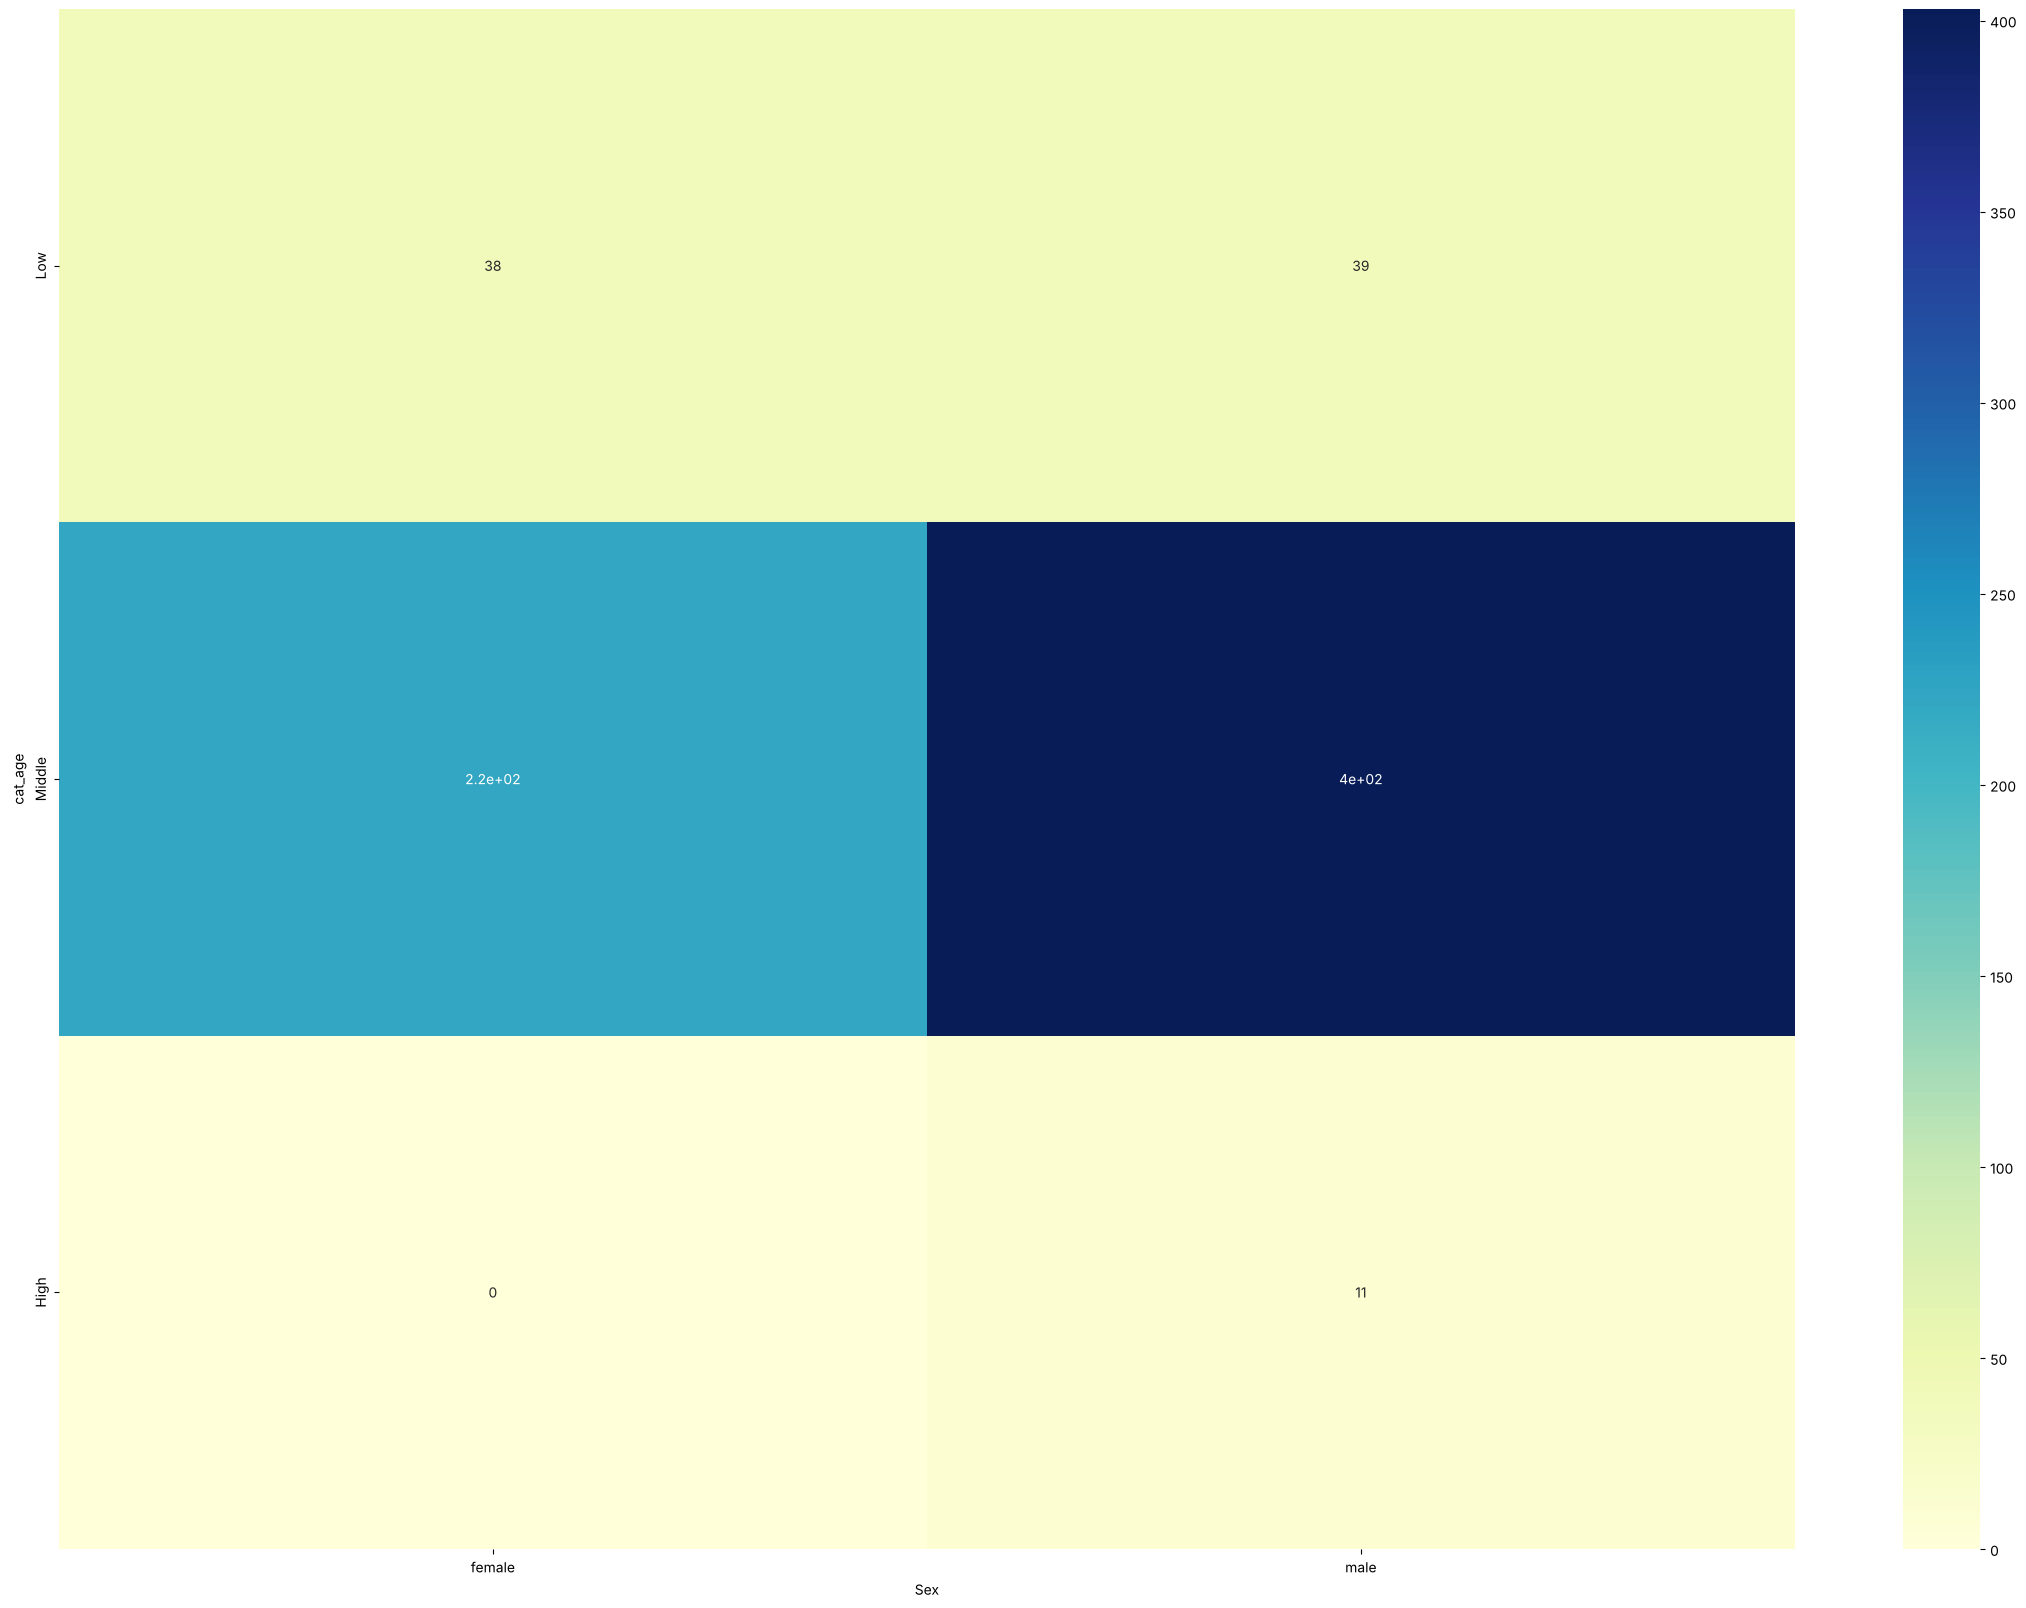

In [14]:
# Why: test whether age group and sex are related (chi-squared test of independence).
# What: crosstab counts the passengers in each age group x sex; chi2_contingency returns the statistic, the p-value, the degrees of freedom and the expected counts.
# Output: a heat map of the counts (darker = more passengers) and p = 0.0025, below 0.05, so age group and sex are related.
# Note: the commented-out lines (# ageTo...) are optional extras; remove the # to see those tables.
# Perform Chi-squared tests of independence on the Age data to check whether it is dependent on the other variables
# Run at a 95% confidence level
# The null hypothesis is that Age and the tested against variable are independent

# Age to sex
# --- Contingency table
ageToSexContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['Sex'])
# ageToSexContigencyTable
# # --- Contingency table with percentages
# ageToSexContigencyTablePercentage = pd.crosstab(trainingData['Age'],trainingData['Sex'], normalize='index')
# ageToSexContigencyTablePercentage
# --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToSexContigencyTable, annot=True, cmap="YlGnBu")
# --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToSexContigencyTable)
p

np.float64(2.597474568852493e-37)

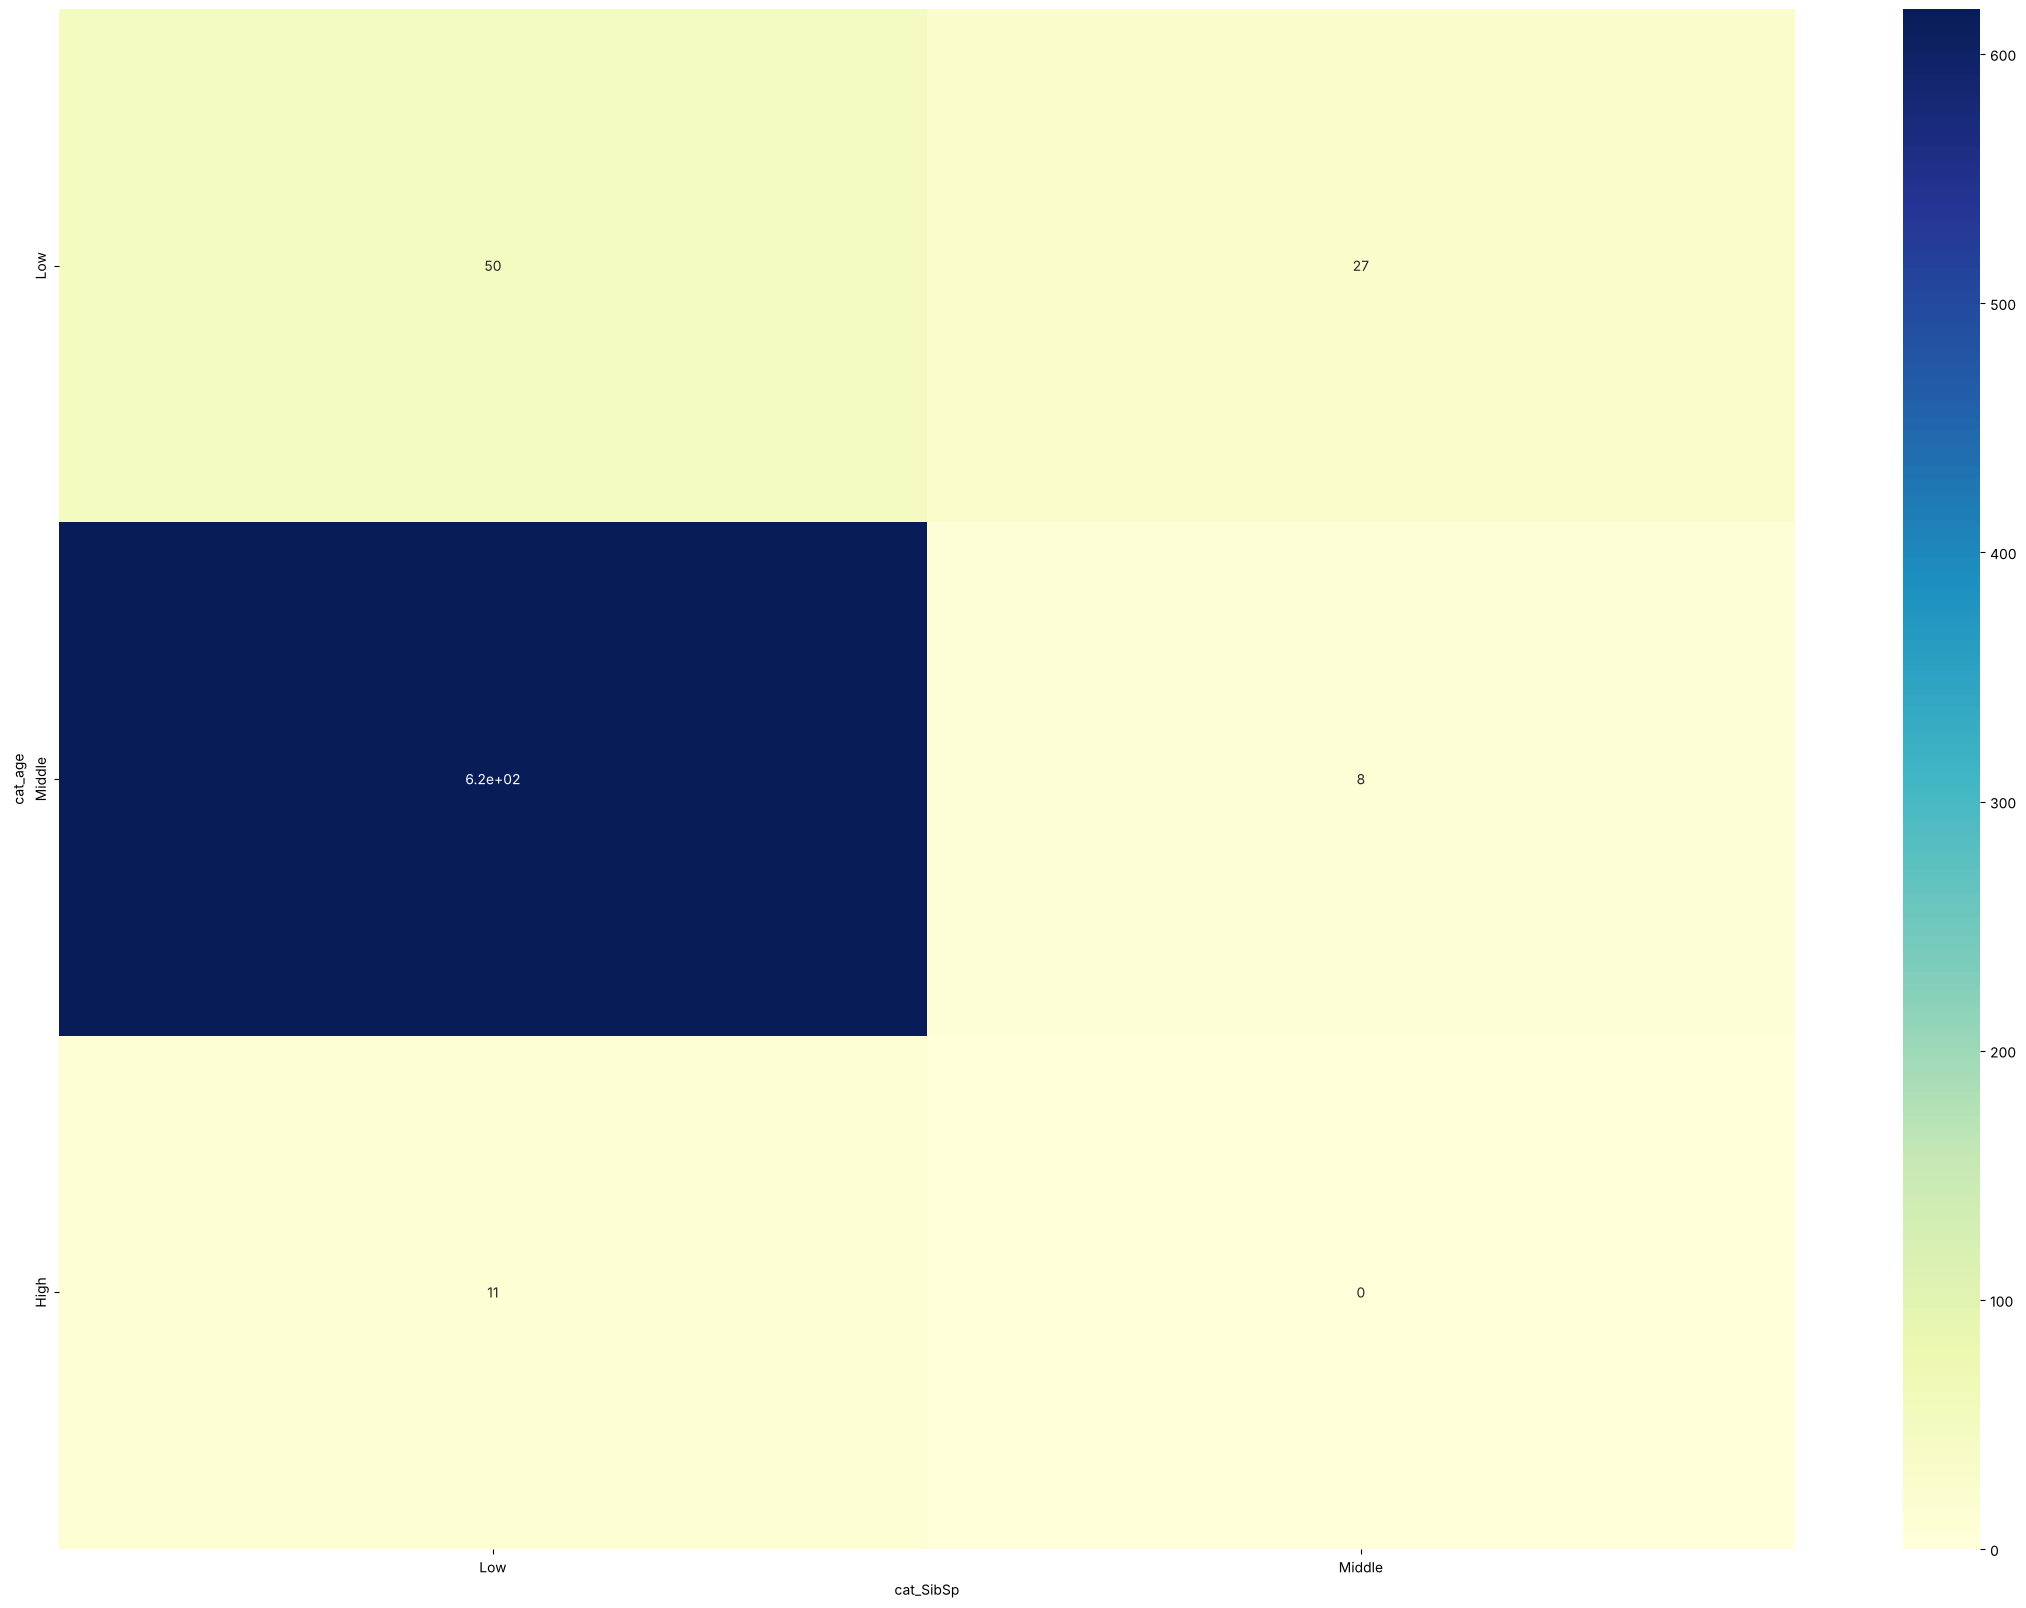

In [15]:
# Why: the same test for age group and number of siblings/spouses (cat_SibSp).
# Output: the heat map and p = 2.6e-37, a tiny number: strongly related.
# Note: the percentage table is calculated but not shown, because a cell only displays the value of its last line.
# Age to SibSp
# --- Contingency table
ageToSibSpContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['cat_SibSp'])
# ageToSibSpContigencyTable
# --- Contingency table with percentages
ageToSibSpContigencyTablePercentage = pd.crosstab(trainingData['Age'],trainingData['SibSp'], normalize='index')
ageToSibSpContigencyTablePercentage
# --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToSibSpContigencyTable, annot=True, cmap="YlGnBu")
# # --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToSibSpContigencyTable)
p


np.float64(0.7074819053773891)

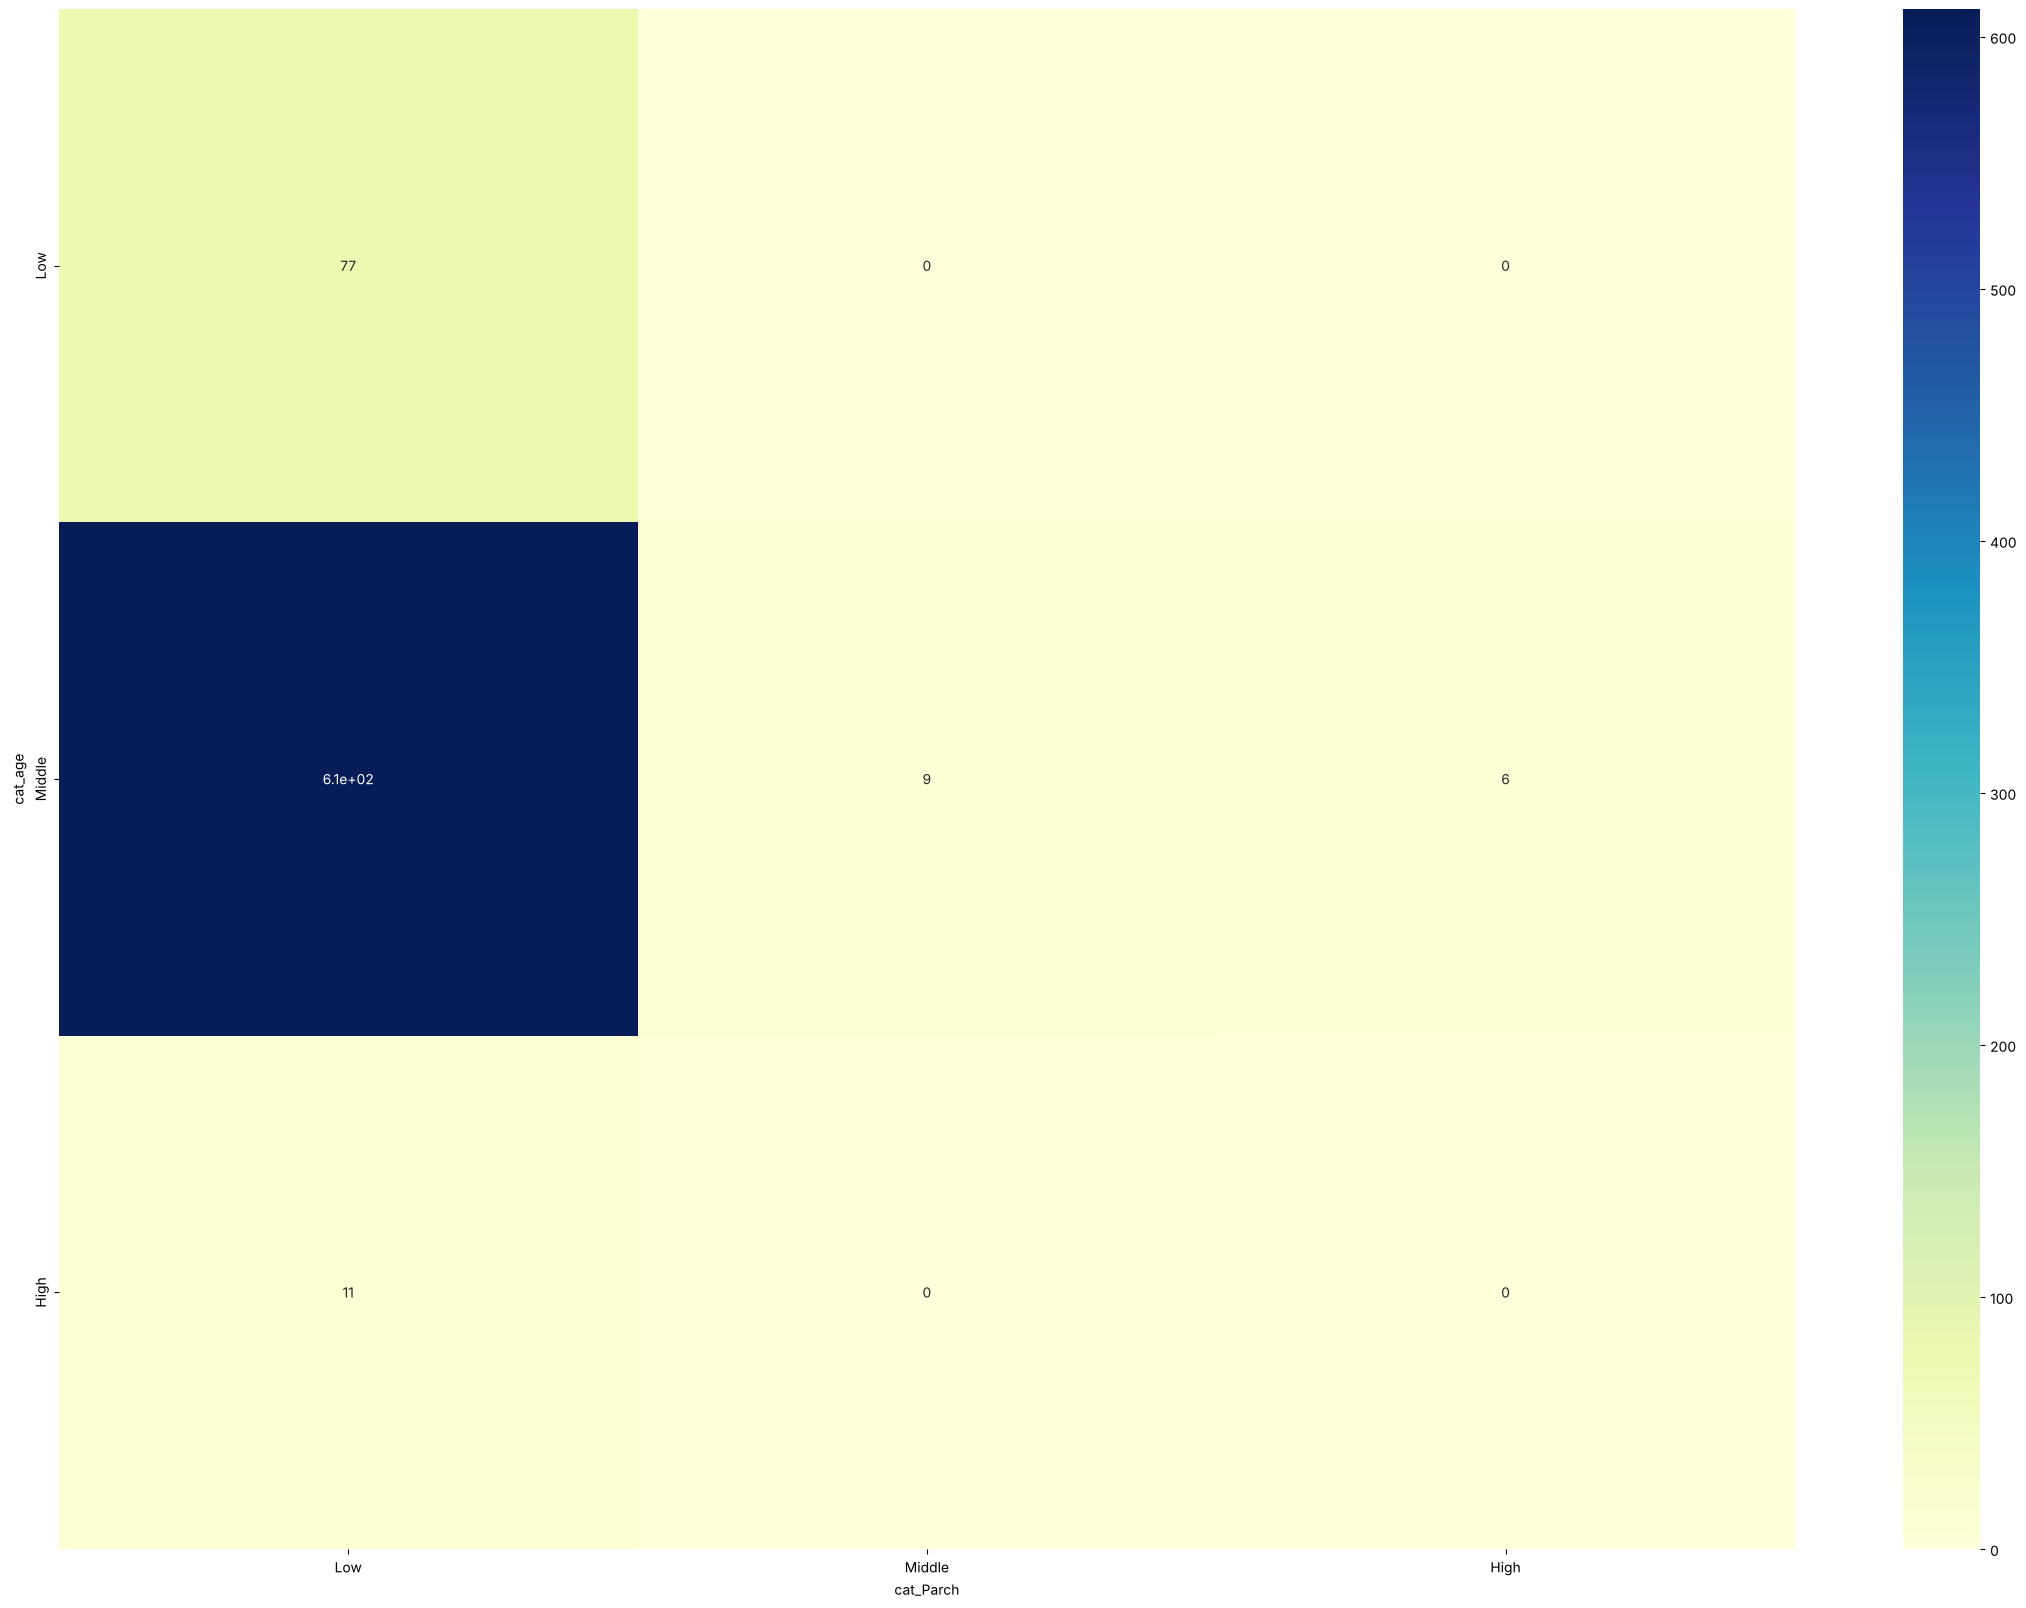

In [16]:
# Why: age group vs. number of parents/children (cat_Parch).
# Output: the heat map and p = 0.71, above 0.05: no evidence of a relationship.
# Age to Parch
# --- Contingency table
ageToParchContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['cat_Parch'])
# ageToSexContigencyTable
# --- Contingency table with percentages
# ageToParchContigencyTablePercentage = pd.crosstab(trainingData['Age'],trainingData['Parch'], normalize='index')
# ageToParchContigencyTablePercentage
# --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToParchContigencyTable, annot=True, cmap="YlGnBu")
# --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToParchContigencyTable)
p

np.float64(0.12035550962724571)

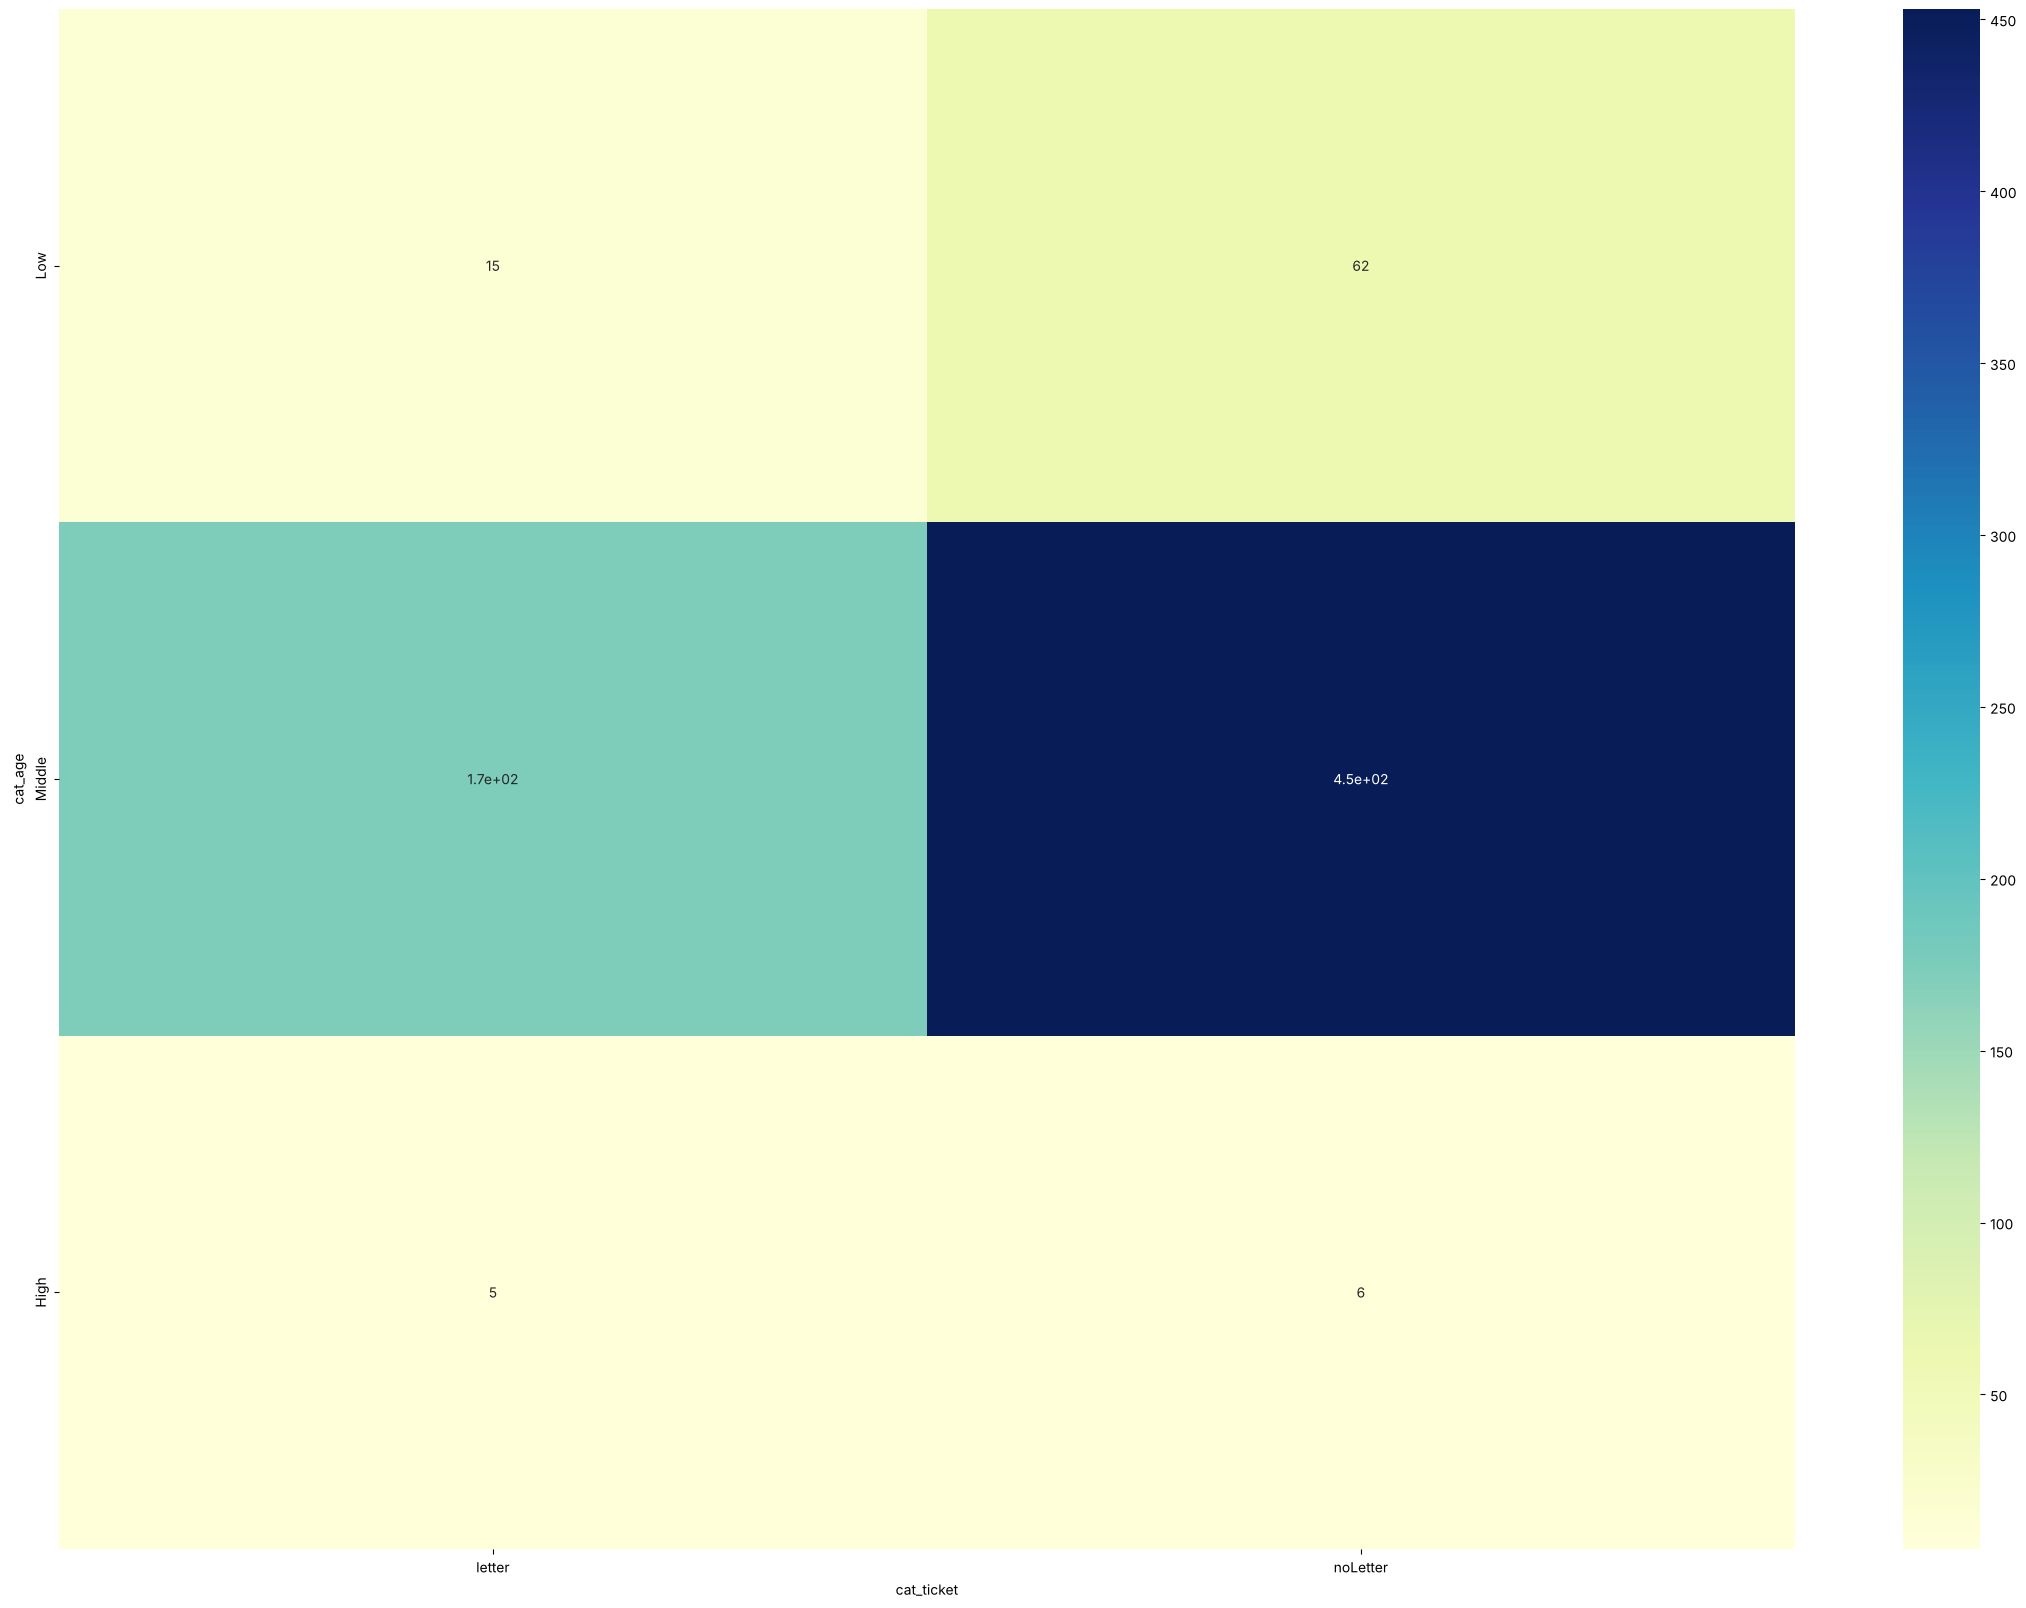

In [17]:
# Why: age group vs. ticket type (letter / noLetter).
# Output: the heat map and p = 0.12, above 0.05: no evidence of a relationship.
# Age to Ticket
# --- Contingency table
ageToTicketContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['cat_ticket'])
# ageToSexContigencyTable
# --- Contingency table with percentages
# ageToTicketContigencyTablePercentage = pd.crosstab(trainingData['Age'],trainingData['Ticket'], normalize='index')
# ageToTicketContigencyTablePercentage
# --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToTicketContigencyTable, annot=True, cmap="YlGnBu")
# # --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToTicketContigencyTable)
p

np.float64(0.7761474570225351)

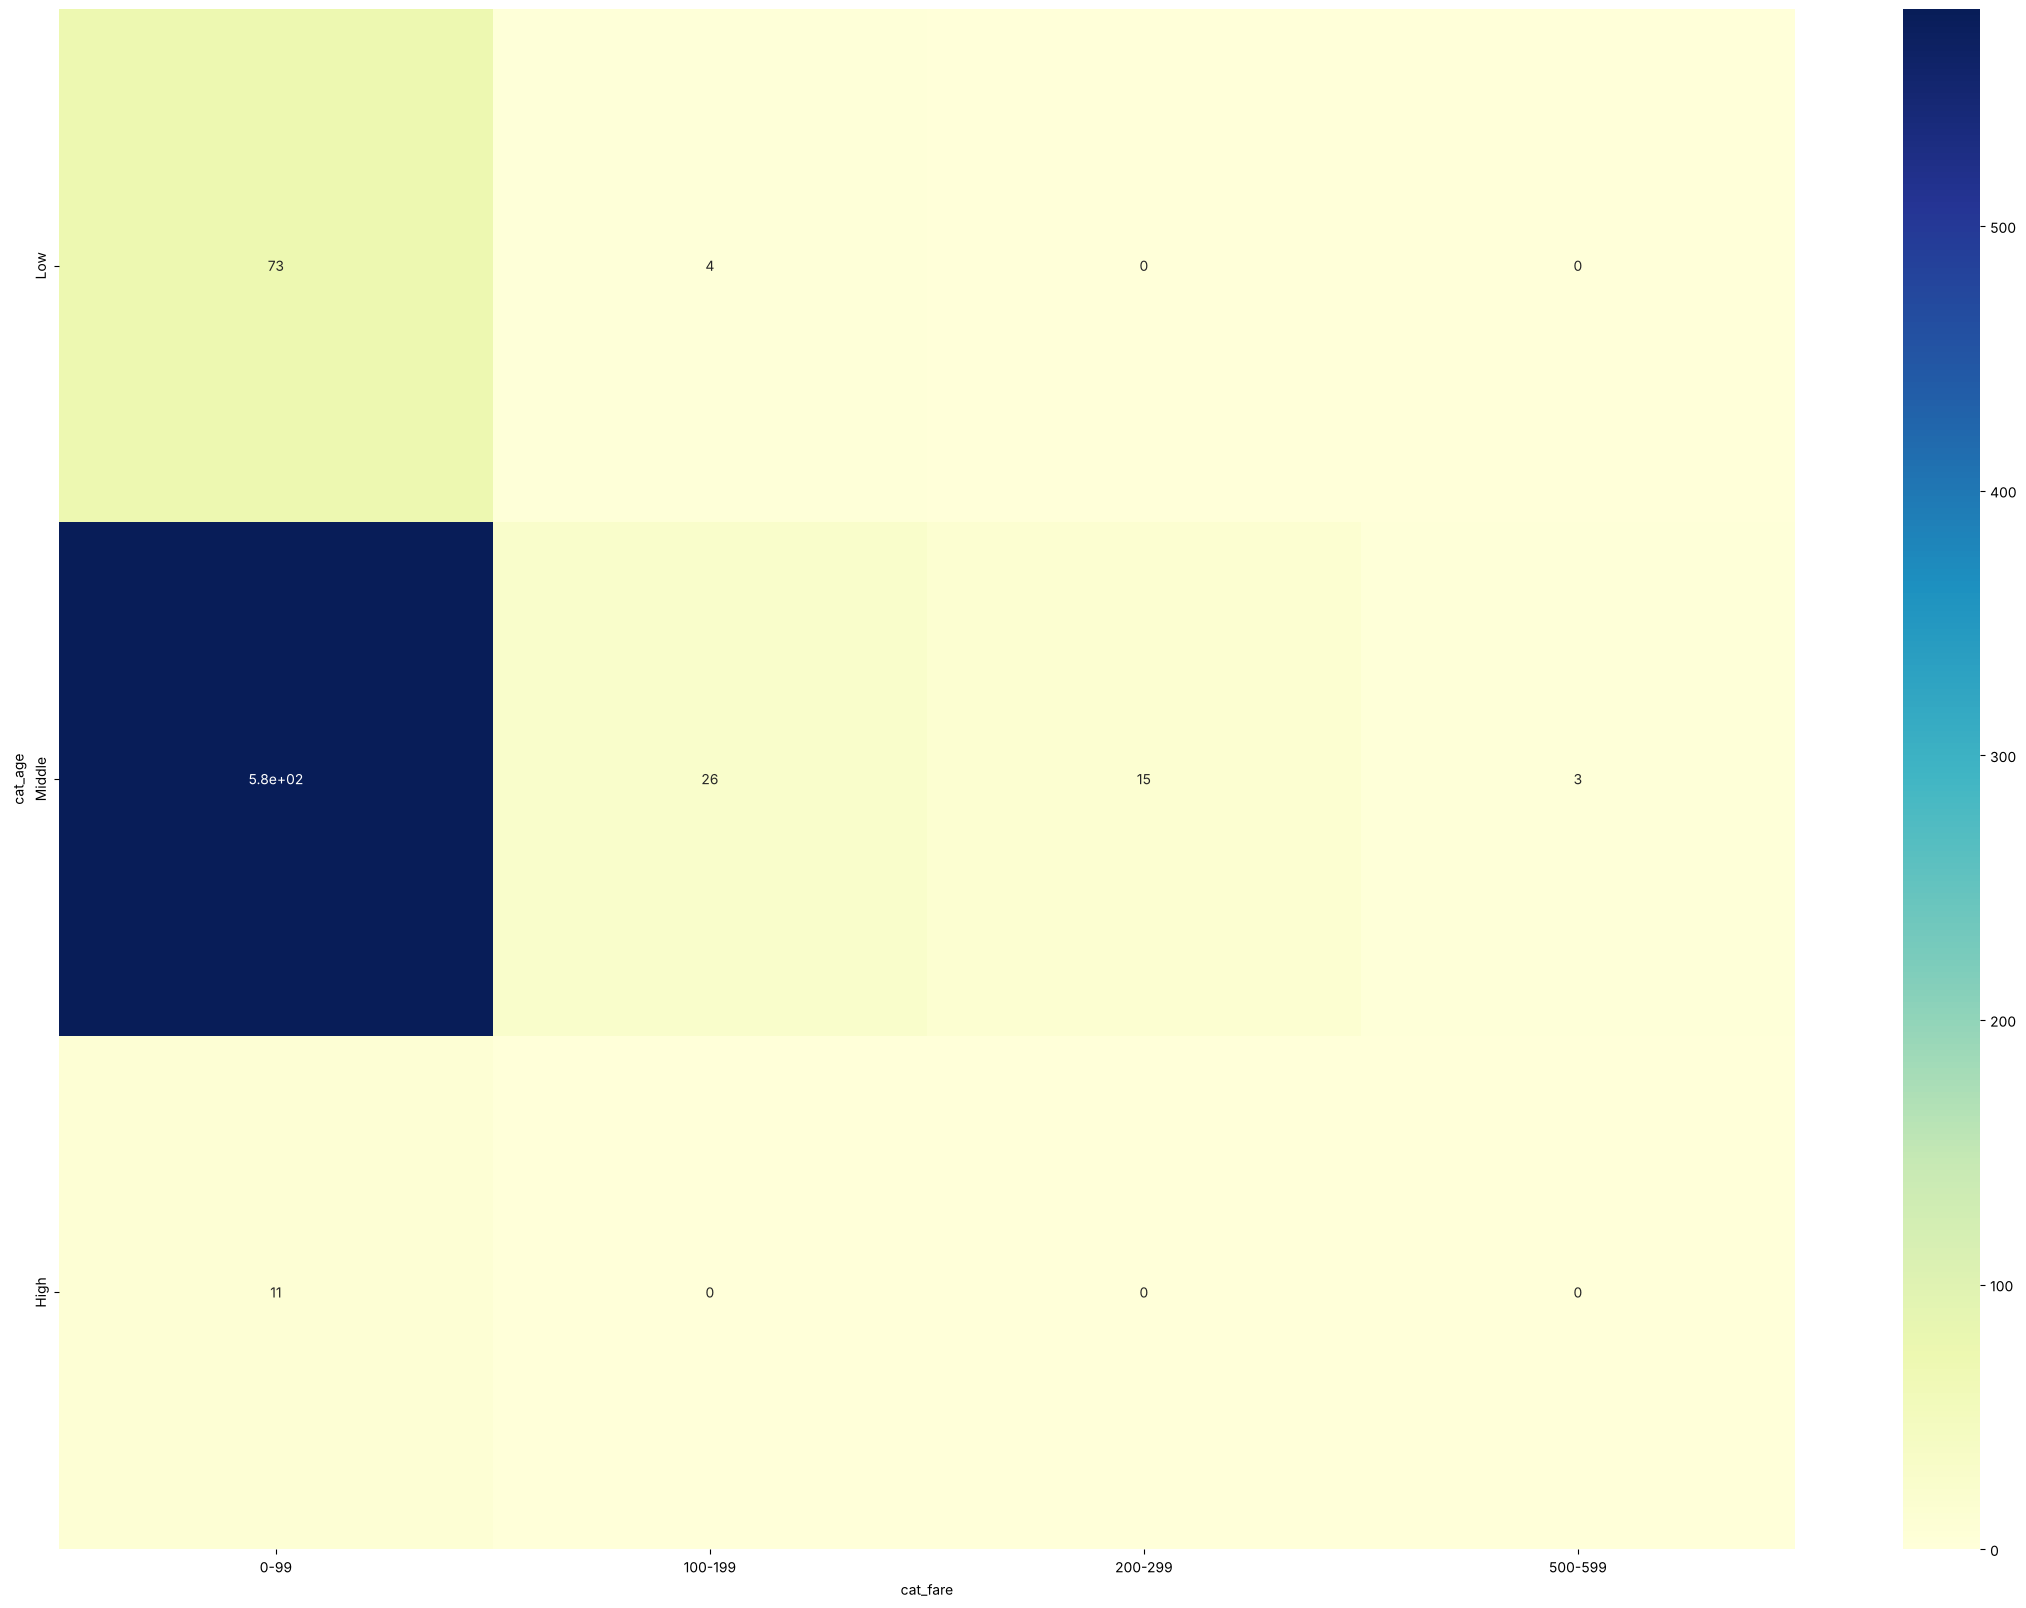

In [18]:
# Why: age group vs. fare band.
# Output: the heat map and p = 0.78, above 0.05: no evidence of a relationship.
# Note: most fares are below 100, so many cells of the table are tiny or empty; the chi-squared test is less reliable then.
# Age to Fare
# --- Contingency table
ageToFareContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['cat_fare'])
# ageToSexContigencyTable
# --- Contingency table with percentages
# ageToFareContigencyTablePercentage = pd.crosstab(trainingData['cat_age'],trainingData['cat_fare'], normalize='index')
# ageToFareContigencyTablePercentage
# # --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToFareContigencyTable, annot=True, cmap="YlGnBu")
# --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToFareContigencyTable)
p

np.float64(0.00012478937929448394)

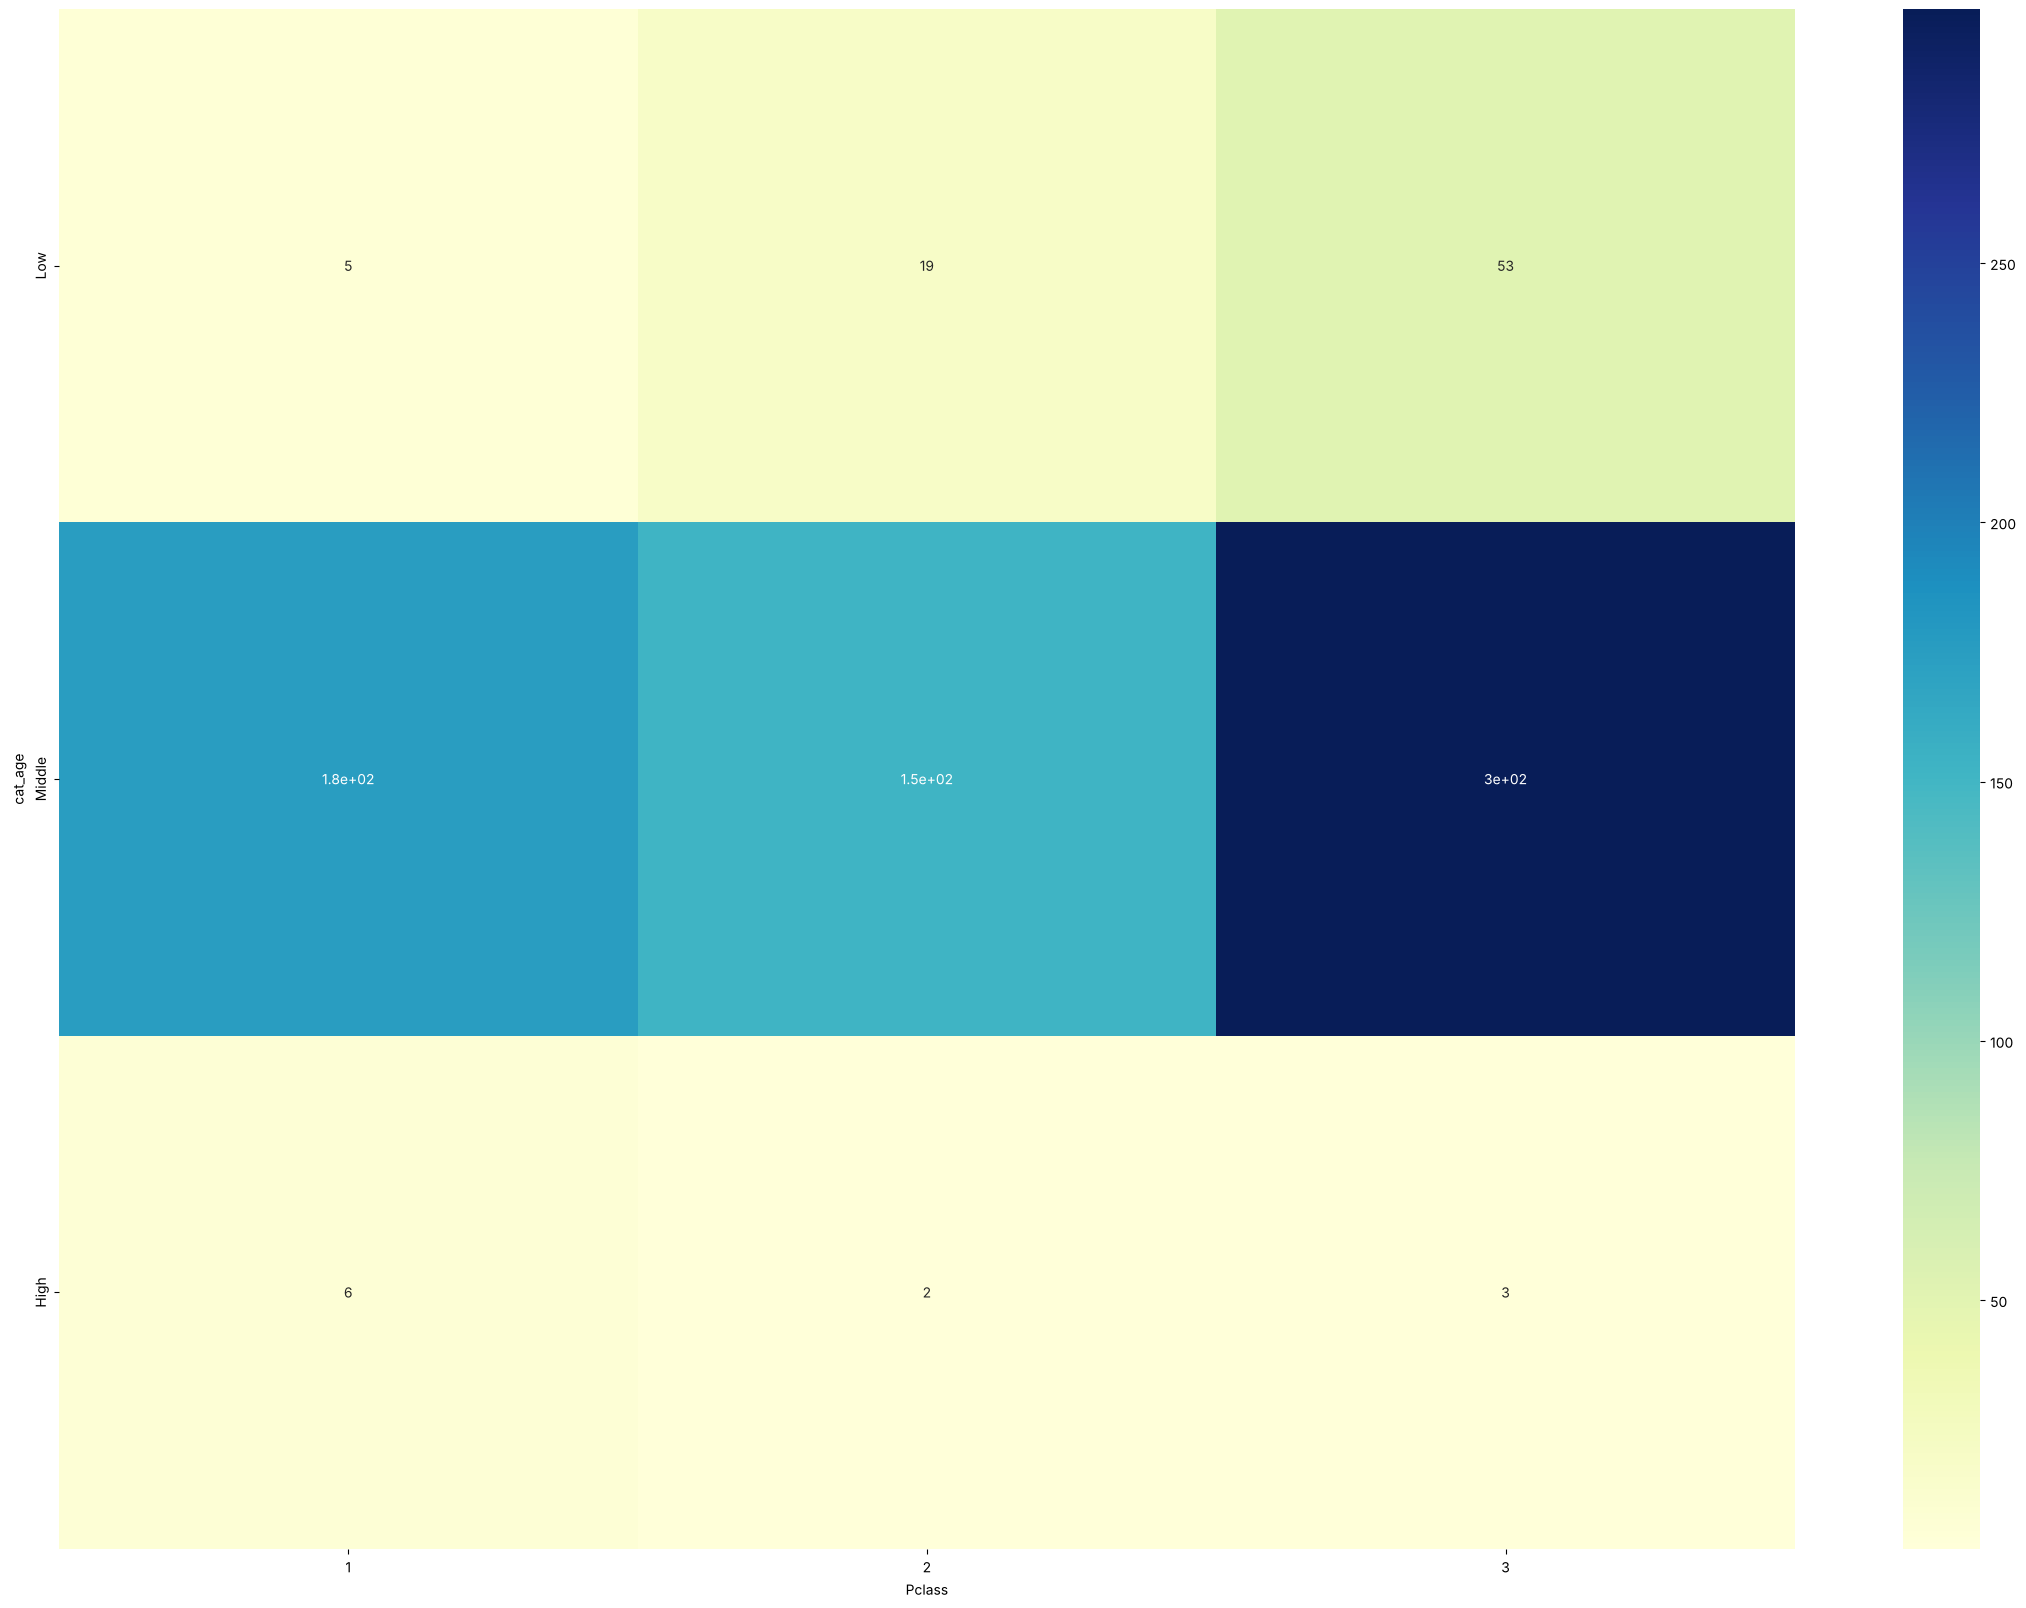

In [19]:
# Why: age group vs. passenger class.
# Output: the heat map and p = 0.00012, below 0.05: age group and class are related.
# Age to Pclass
# --- Contingency table
ageToPclassContigencyTable = pd.crosstab(trainingData['cat_age'],trainingData['Pclass'])
# ageToPclassContigencyTable
# # --- Contingency tables in heat map form
matplot.figure(figsize=(28,20))
seaborn.heatmap(ageToPclassContigencyTable, annot=True, cmap="YlGnBu")
# --- Run the Chi-squared test
c, p, dof, expected = chi2_contingency(ageToPclassContigencyTable)
p

The dendrogram groups columns whose missing values tend to occur together: columns joined near the bottom have very similar patterns of missingness.

<Axes: >

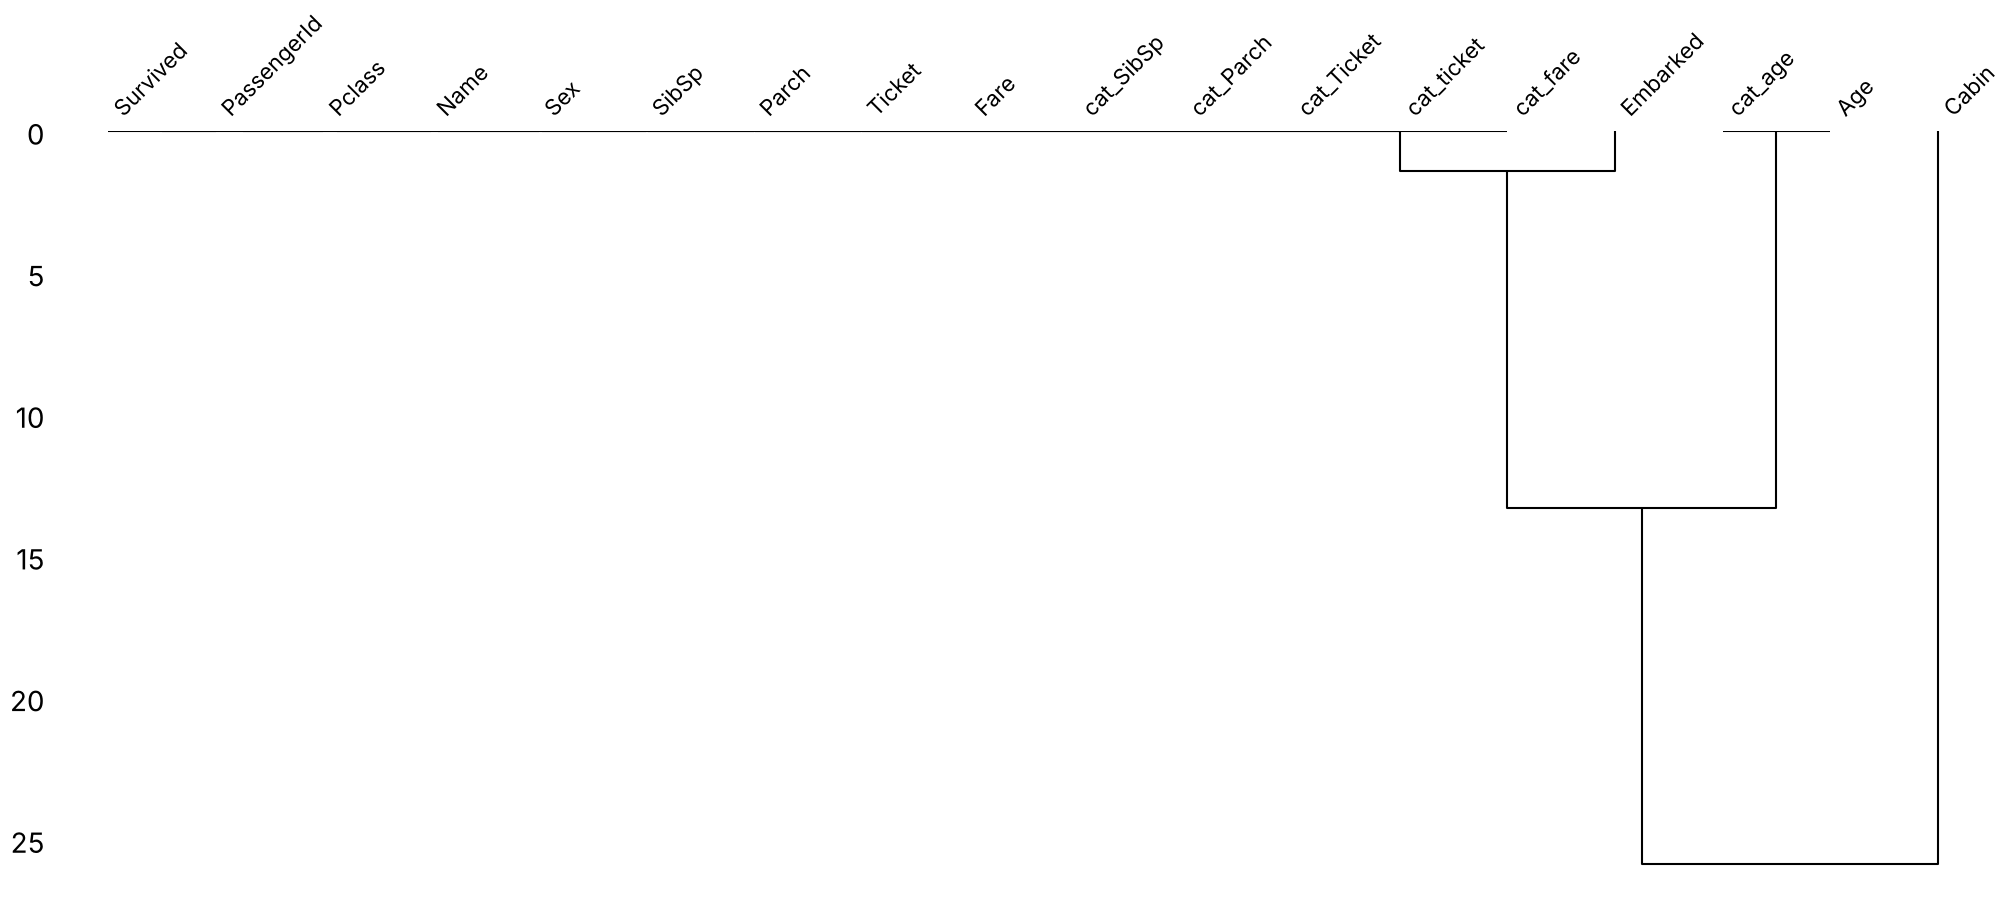

In [20]:
# Why: see which columns tend to be missing together.
# Output: a tree diagram; columns joined near the bottom have similar patterns of missing values. The `<Axes: >` text can be ignored.
# Draw a dendrogram to visualise the correlations and missingness
misnum.dendrogram(trainingData)

### Impute the missing ages

`IterativeImputer` normally predicts a missing value from the other columns. Here it is given only the `Age` column, so it has nothing to predict from and simply fills every gap with the mean age, 29.699118 (you can see it for passenger 888 in the output). This is the *attribute mean* method from the lecture.

In [21]:
# Why: fill the 177 missing ages so that later steps can use every passenger.
# What: given only the Age column, IterativeImputer has nothing to learn from and fills each gap with the mean age.
# Output: the Age column; row 888 shows the filled-in value 29.699118.
# Note: cat_age was made before this step, so it still has no group for these 177 passengers.
# Impute the 'age' data using the iterative imputer
# The code was adapted from the example in the documentation: https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html
imp = IterativeImputer(max_iter=10, verbose=1, random_state=1)
trainingData['Age'] = imp.fit_transform(trainingData[['Age']])
print(trainingData['Age'])

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64


### Encode and impute `Embarked`

These cells turn the port codes into numbers (S = 0, C = 1, Q = 2) and then try to impute the missing values with the mean.

⚠️ Two problems: the `else` branch also catches the two missing values, so they become 2 (Q) instead of staying missing; and `imp.transform(...)` returns a new array that is never stored, so the column does not change. The mean of a category code would not be a sensible value anyway: the most frequent port (S) is the usual choice for a categorical column. `Embarked` is not used in the analysis below, so the results are not affected.

In [22]:
# Why: turn the port letters into numbers.
# Output: none.
# Note: the else branch also catches the 2 missing values, so they become 2 (Q); see the note above.
# Convert the 'embarked' code to numeric data for imputation
# S = 0, C = 1 and Q = 2
new_embarked = []
current_embarked = trainingData['Embarked']
for item in current_embarked:
    if item == 'S':
        new_embarked.append(0)
    elif item == 'C':
        new_embarked.append(1)
    else:
        new_embarked.append(2)
trainingData['Embarked'] = new_embarked

In [23]:
# Output: the Embarked column now holds the numbers 0, 1 and 2 (dtype int64).
print(trainingData['Embarked'])

0      0
1      1
2      0
3      0
4      0
      ..
886    0
887    0
888    0
889    1
890    2
Name: Embarked, Length: 891, dtype: int64


In [24]:
# Why: meant to fill missing Embarked values with the column mean.
# Output: the same column as in the previous cell: nothing changed.
# Impute the 'embarked' data using the 'mean' imputation method
# This code was adapted from the example code in the documentation https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html
imp = SimpleImputer(missing_values=np.nan, strategy='mean')
imp.fit(trainingData[['Embarked']])
imp.transform(trainingData[['Embarked']])  # returns a new array that is not stored, so the column is unchanged
print(trainingData['Embarked'])

0      0
1      1
2      0
3      0
4      0
      ..
886    0
887    0
888    0
889    1
890    2
Name: Embarked, Length: 891, dtype: int64


### Look for noisy data and outliers in `Age`

The ages are split into men and women, `describe()` gives their summary statistics, and the histograms show their distributions. The tall bar near 30 in both histograms is the 177 imputed ages, all equal to the mean.

In [25]:
# Why: split the ages by sex, because men and women may have different age distributions.
# Output: none. `.loc[condition]` and `[condition]` select the same rows here.
# Check for noisy data in the age data
# Trim the dataset down to just the age and into two datasets of male and female, respectively
trainingDataAgeSex = trainingData[['Age','Sex']]
trainingDataMale = trainingDataAgeSex.loc[trainingDataAgeSex['Sex'] == 'male']
trainingDataFemale = trainingDataAgeSex[trainingDataAgeSex['Sex'] == 'female']
# print(trainingDataMale)

In [26]:
# Output: statistics for the 577 men: mean 30.5, std 13.0, ages from 0.42 to 80.
# The median (50%) is the filled-in mean age 29.699118, because so many values are equal to it.
# Identify statistical information about the male dataset that was defined above
trainingDataMale.describe()

,Age
count,577.000000
mean,30.505824
std,13.009478
min,0.420000
25%,23.000000
50%,29.699118
75%,35.000000
max,80.000000


In [27]:
# Output: statistics for the 314 women: mean 28.2, std 12.9, ages from 0.75 to 63.
# Identify statistical information about the female dataset that was defined above
trainingDataFemale.describe()

,Age
count,314.000000
mean,28.216730
std,12.877543
min,0.750000
25%,21.000000
50%,29.699118
75%,35.000000
max,63.000000


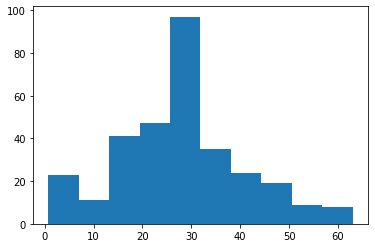

In [28]:
# Why: a histogram shows how many women fall into each age range.
# Output: a bar chart; the tall bar near 30 contains the filled-in mean ages.
# Note: the ; at the end hides the text that hist() returns, so only the picture is shown.
# Draw histograms to identify noisy data in men and women's ages, respectively
# For women:
xAxisFemale = trainingDataFemale['Age']
matplot.hist(xAxisFemale);

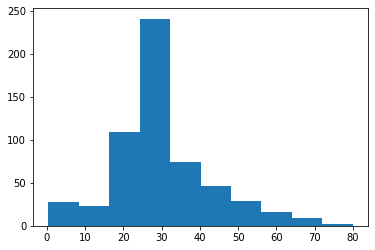

In [29]:
# Output: the same histogram for the men, again with a tall bar near 30.
# For men:
xAxisMale = trainingDataMale['Age']
matplot.hist(xAxisMale);

The next two cells treat ages more than about one standard deviation from the mean as outliers (for men 30.5 ± 13.0, for women 28.2 ± 12.9) and print them. The last number is the share of outliers among men, and then among women.

In [30]:
# Why: count the men whose age is more than one standard deviation (SD) from the mean, as possible outliers.
# Output: the 58 younger and the 85 older men, then 0.2478..., about 25% of the men.
# Note: about 32% of normally distributed values lie outside mean +/- 1 SD, so this rule marks many ordinary ages.
# Count the number of men below 17.496 or above 43.515 (mean 30.506 -/+ SD 13.009)
print(trainingDataMale[trainingDataMale['Age']<17.496])# those below are 58 in number
print(trainingDataMale[trainingDataMale['Age']>43.515])# those above are 85 in number
print((85+58)/577) # the share of men whose ages are outliers - 24.8%

       Age   Sex
7     2.00  male
16    2.00  male
50    7.00  male
59   11.00  male
63    4.00  male
78    0.83  male
86   16.00  male
125  12.00  male
138  16.00  male
163  17.00  male
164   1.00  male
165   9.00  male
171   4.00  male
182   9.00  male
183   1.00  male
193   3.00  male
220  16.00  male
261   3.00  male
266  16.00  male
278   7.00  male
282  16.00  male
305   0.92  male
333  16.00  male
340   2.00  male
348   3.00  male
352  15.00  male
386   1.00  male
407   3.00  male
433  17.00  male
445   4.00  male
480   9.00  male
489   9.00  male
500  17.00  male
532  17.00  male
549   8.00  male
550  17.00  male
574  16.00  male
683  14.00  male
686  14.00  male
721  17.00  male
731  11.00  male
746  16.00  male
751   6.00  male
755   0.67  male
764  16.00  male
787   8.00  male
788   1.00  male
791  16.00  male
802  11.00  male
803   0.42  male
819  10.00  male
824   2.00  male
827   1.00  male
831   0.83  male
841  16.00  male
844  17.00  male
850   4.00  male
869   4.00  ma

In [31]:
# Why: the same check for the women (mean 28.217 +/- SD 12.878).
# Output: the 43 younger and the 44 older women, then 0.2770..., about 28% of the women.
# Count the number of women below 15.339 or above 41.095
print(trainingDataFemale[trainingDataFemale['Age']<15.339])# those below are 43 in number
print(trainingDataFemale[trainingDataFemale['Age']>41.095])# those above are 44 in number
print((44+43)/314) # the share of women whose ages are outliers - 27.7%

       Age     Sex
9    14.00  female
10    4.00  female
14   14.00  female
22   15.00  female
24    8.00  female
39   14.00  female
43    3.00  female
58    5.00  female
111  14.50  female
119   2.00  female
147   9.00  female
172   1.00  female
184   4.00  female
205   2.00  female
233   5.00  female
237   8.00  female
297   2.00  female
374   3.00  female
381   1.00  female
419  10.00  female
435  14.00  female
446  13.00  female
448   5.00  female
469   0.75  female
479   2.00  female
530   2.00  female
535   7.00  female
541   9.00  female
542  11.00  female
618   4.00  female
634   9.00  female
642   2.00  female
644   0.75  female
689  15.00  female
691   4.00  female
720   6.00  female
750   4.00  female
777   5.00  female
780  13.00  female
813   6.00  female
830  15.00  female
852   9.00  female
875  15.00  female
      Age     Sex
11   58.0  female
15   55.0  female
52   49.0  female
132  47.0  female
167  45.0  female
177  50.0  female
194  44.0  female
195  58.0  female
25

### Men and women on board

A bar chart of the number of men (577) and women (314), and the ratio of men to women (about 1.84).

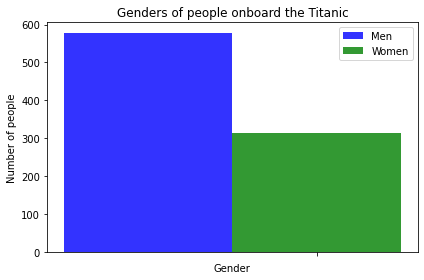

In [32]:
# Why: compare the number of men and women in a bar chart.
# Output: a blue bar (577 men) and a green bar (314 women) with a legend; the x-axis has no labels.
# Note: the counts are typed in; trainingData['Sex'].value_counts() would calculate them.
# Show the distribution of men and women on a bar chart
# I used code from here https://pythonspot.com/matplotlib-bar-chart/

# data to plot
noOfWomen = 314
noOfMen = 577
noOfDataSets = 1

# create plot
fig, ax = matplot.subplots()
index = np.arange(noOfDataSets)
bar_width = 0.35
opacity = 0.8

rects1 = matplot.bar(index, noOfMen, bar_width,
alpha=opacity,
color='b',
label='Men')

rects2 = matplot.bar(index + bar_width, noOfWomen, bar_width,
alpha=opacity,
color='g',
label='Women')

matplot.xlabel('Gender')
matplot.ylabel('Number of people')
matplot.title('Genders of people onboard the Titanic')
matplot.xticks(index + bar_width, ())  # () means no tick labels
matplot.legend()

matplot.tight_layout()
matplot.show()

In [33]:
# Output: 1.8375...: there were about 1.84 men for every woman.
# Calculate a ratio of men and women
print(577/314)

1.8375796178343948


⚠️ The next cell is meant to give the average number of children per woman, but `Parch` counts parents **and** children, for **all** 891 passengers, and the result is divided by the number of women over 29 (167). The value 2.04 therefore does not measure children per woman. The following cell plots `Age`, `Sex` and `Parch` for the women over 29.

In [34]:
# Why: meant to estimate the number of children per woman; the note above explains why the result does not measure that.
# Output: 167 (women over 29), 340 (sum of Parch over all passengers) and 340 / 167 = 2.04.
# Note: the numbers are typed in by hand, and `over29` is created but not used.
# Meant to calculate the average number of children per woman
over29 = (trainingDataFemale[trainingDataFemale['Age']>29])
noOver29 = 167
noOfChildren = trainingData['Parch'].sum()
print(noOver29)
print(noOfChildren)
print(340/167)

167
340
2.035928143712575


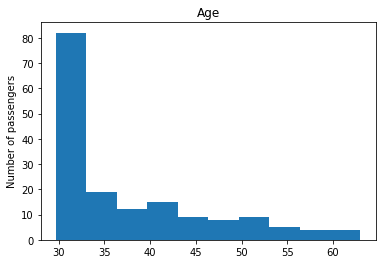

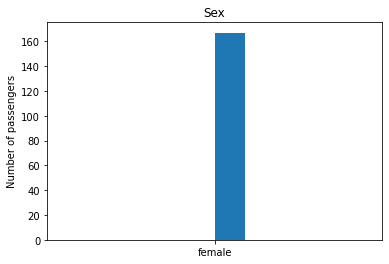

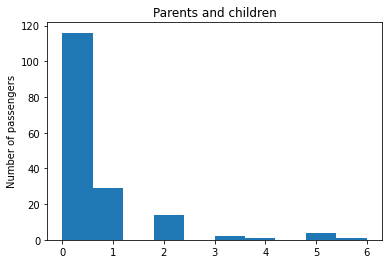

In [35]:
# Why: look more closely at the women over 29.
# Output: three histograms, one per column (Age, Sex, Parch), for the 167 women over 29.
# Note: the counts 6 and 145 and the limits 3.112 and 1.5 are typed in; the limits are not this group's mean +/- SD (0.56 +/- 1.11).
# TODO: verify where the limits 3.112 and 1.5 come from.
# Check for outliers in the number of children
selectedData = trainingData[['Age','Sex','Parch']]
selectedAge = selectedData[selectedData['Age']>29]
selectedWomen = selectedAge[selectedAge['Sex']=='female']
# Count the number of women children above the S.D (above 3.112)
# print(selectedWomen[selectedWomen['Parch']>3.112])
highOutlier = 6
# Count the number of women children below the S.D (below 1.5)
# print(selectedWomen[selectedWomen['Parch']<1.5])
lowOutlier = 145

totalWomen = 314
totaOutlier = 151
ratio = (151/314)

# Draw one histogram per column for the women over 29 (with or without children)
for iteration in selectedWomen.columns:
    matplot.hist(selectedWomen[iteration])
    if iteration == 'SibSp':
        title = 'Siblings and spouses'
    elif iteration == 'Parch':
        title = 'Parents and children'
    else:
        title = iteration
    matplot.title(title)
    matplot.ylabel('Number of passengers')
    matplot.show()

### Check the other numeric columns for noise

A histogram of `Pclass` and the summary statistics of `SibSp`. Most passengers travelled without siblings or a spouse (median 0), but a few have 5 or 8.

<Axes: >

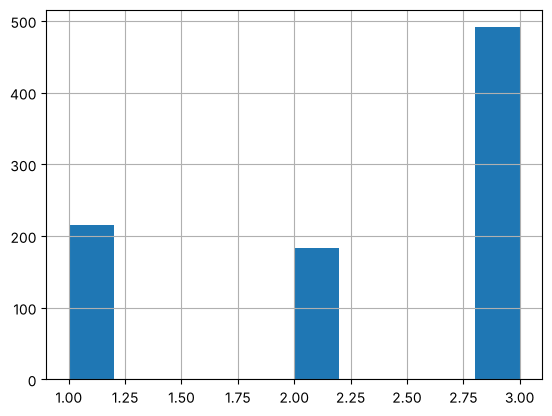

In [36]:
# Why: check Pclass for impossible values (noise); only 1, 2 and 3 should appear.
# Output: a histogram with bars only at 1, 2 and 3, so there is no noise. The `<Axes: >` text can be ignored.
# Draw a bar chart of 'Pclass' to check for noise
trainingData['Pclass'].hist()

In [37]:
# Output: SibSp statistics: mean 0.52, median (50%) 0, max 8; the few 5s and 8s are far from the rest.
trainingData['SibSp'].describe()

count    891.000000
mean       0.523008
std        1.102743
min        0.000000
25%        0.000000
50%        0.000000
75%        1.000000
max        8.000000
Name: SibSp, dtype: float64

⚠️ This cell is meant to replace the extreme `SibSp` values (5 and 8) with the mean, but it changes nothing: no value can be 8 **and** 5 at the same time, so the selection is always empty, and the `==` only compares values instead of assigning them. A working version would be `trainingData.loc[trainingData['SibSp'].isin([5, 8]), 'SibSp'] = sibSpMean`.

In [38]:
# Why: meant to replace the extreme SibSp values (5 and 8) with the mean.
# Output: an empty table and 0.523008: nothing was replaced (see the note above).
# Clean out the noisy data of 'SibSp' and replace it with the mean
sibSpMean = 0.523008
trainingData.loc[(trainingData['SibSp']==8) & (trainingData['SibSp']==5)] == 0.523008,0.523008

(Empty DataFrame
 Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked, cat_age, cat_SibSp, cat_Parch, cat_Ticket, cat_ticket, cat_fare]
 Index: [],
 0.523008)

Histograms of the four numeric columns. `SibSp`, `Parch` and `Fare` are strongly right-skewed: most values are small and a few are very large.

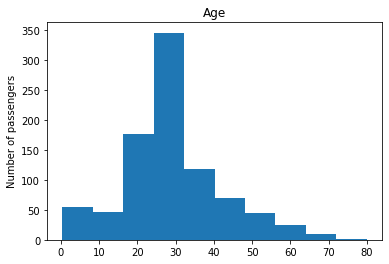

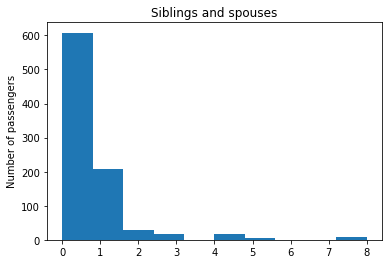

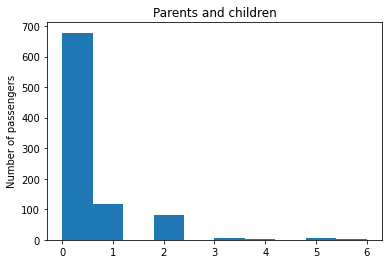

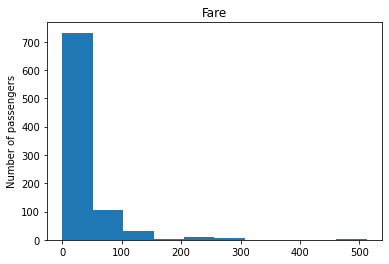

In [39]:
# Why: look at the shape of each numeric column.
# Output: four histograms (Age, Siblings and spouses, Parents and children, Fare); the last three are right-skewed.
# Note: the 'binnedSibsp' branch is never used, because there is no such column.
# Show quantitative data in histograms
quanTrainingData = trainingData[['Age','SibSp','Parch','Fare']]
for iteration in quanTrainingData.columns:
    matplot.hist(quanTrainingData[iteration])
    if iteration == 'SibSp':
        title = 'Siblings and spouses'
    elif iteration == 'Parch':
        title = 'Parents and children'
    elif iteration == 'binnedSibsp':
        title = 'Binned Siblings and Spouses'
    else:
        title = iteration
    matplot.title(title)
    matplot.ylabel('Number of passengers')
    matplot.show()

Counts of passengers over 15, of men and women over 15, and of those over 15 with at least one sibling or spouse on board. The numbers (808, 537, 271 and 223) are typed in by hand from the filtered tables and are not used later.

In [40]:
# Why: count the adult passengers, and those of them with siblings or a spouse on board.
# Output: none; nothing is printed and the counts are not used later.
# Note: the names say 'Over16', but the condition is Age > 15.
# Check the number of people over 15 with at least one sibling or spouse on board
peopleOver16 = (trainingData[trainingData.Age > 15])
noOver16 = 808
over16Men = peopleOver16[peopleOver16.Sex == 'male']
noOver16Men = 537
over16Women = peopleOver16[peopleOver16.Sex == 'female']
noOver16Women = 271
over16MarriedOrSpouse = peopleOver16[peopleOver16.SibSp != 0]
noOver16Married =223

### Transform and normalise

`log(x + 1)` reduces the right skew of `SibSp` and `Fare` (the lecture's slide "Dealing with skewed distributions"); the `+ 1` avoids `log(0)`. The originals are kept in backup variables, and a bar chart shows the distribution of `Parch`. `MinMaxScaler` then rescales `Age`, the log-transformed `SibSp`, `Parch` and the log-transformed `Fare` to the range 0–1 in a copy of the table, `all_data_scaled` (the lecture's step "Data normalization").

<Axes: >

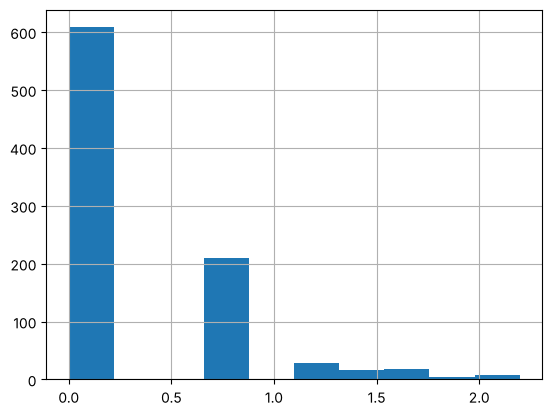

In [41]:
# Why: log(x + 1) squeezes large values together, so the skewed SibSp becomes more balanced; the + 1 avoids log(0).
# Output: a histogram of norm_SibSp; most values are still 0 (no siblings or spouse).
# Log-transform SibSp to reduce its right skew
# Backup the non-standardised data
trainingDataSibSp_nonStandard = trainingData['SibSp']
trainingData['norm_SibSp'] = np.log(trainingData.SibSp+1)
trainingData['norm_SibSp'].hist()

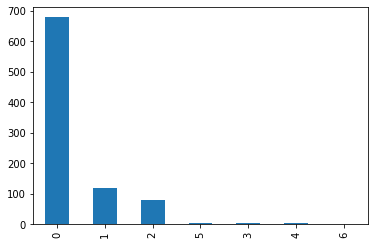

In [42]:
# Output: one bar per Parch value; most passengers have 0.
# Note: value_counts() sorts the bars by count, not by value, so the x-axis is not in numeric order.
# A bar chart of all of the 'Parch' data to check its distribution
trainingData['Parch'].value_counts().plot(kind='bar');

<Axes: >

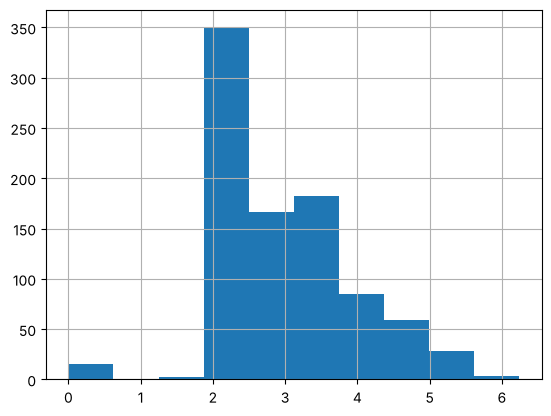

In [43]:
# Why: the same log transformation for Fare.
# Output: a histogram of norm_Fare, much less skewed than the raw fares.
# Log-transform the fare to reduce its right skew
# Backup the non-standardised data
trainingDataFare_nonStandard = trainingData['Fare']
trainingData['norm_Fare'] = np.log(trainingData.Fare+1)
trainingData['norm_Fare'].hist()

In [44]:
# Why: rescale four numeric columns to the range 0-1, so that large numbers (Fare) do not dominate models that compare distances.
# What: fit_transform learns each column's min and max and maps min -> 0 and max -> 1, in a copy called all_data_scaled.
# Output: the scaled table (891 rows x 20 columns); trainingData itself is unchanged.
# Note: all_data_scaled is not used later.
# Normalise the numeric data to the range 0-1 with the min-max scaler
scale = preprocessing.MinMaxScaler()
all_data_scaled = trainingData.copy()
all_data_scaled[['Age','norm_SibSp','Parch','norm_Fare']]= scale.fit_transform(all_data_scaled[['Age','norm_SibSp','Parch','norm_Fare']])
all_data_scaled

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,cat_age,cat_SibSp,cat_Parch,cat_Ticket,cat_ticket,cat_fare,norm_SibSp,norm_Fare
0,1,0,3,"Braund, Mr. Owen Harris",male,0.271174,1,0.000000,A/5 21171,7.2500,NaN,0,Middle,Low,Low,A/5 21171,letter,0-99,0.315465,0.338125
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0.472229,1,0.000000,PC 17599,71.2833,C85,1,Middle,Low,Low,PC 17599,letter,0-99,0.315465,0.685892
2,3,1,3,"Heikkinen, Miss. Laina",female,0.321438,0,0.000000,STON/O2. 3101282,7.9250,NaN,0,Middle,Low,Low,STON/O2. 3101282,letter,0-99,0.000000,0.350727
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0.434531,1,0.000000,113803,53.1000,C123,0,Middle,Low,Low,113803,noLetter,0-99,0.315465,0.639463
4,5,0,3,"Allen, Mr. William Henry",male,0.434531,0,0.000000,373450,8.0500,NaN,0,Middle,Low,Low,373450,noLetter,0-99,0.000000,0.352955
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,0.334004,0,0.000000,211536,13.0000,NaN,0,Middle,Low,Low,211536,noLetter,0-99,0.000000,0.422864
887,888,1,1,"Graham, Miss. Margaret Edith",female,0.233476,0,0.000000,112053,30.0000,B42,0,Middle,Low,Low,112053,noLetter,0-99,0.000000,0.550238
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,0.367921,1,0.333333,W./C. 6607,23.4500,NaN,0,NaN,Low,Low,W./C. 6607,letter,0-99,0.315465,0.512205
889,890,1,1,"Behr, Mr. Karl Howell",male,0.321438,0,0.000000,111369,30.0000,C148,1,Middle,Low,Low,111369,noLetter,0-99,0.000000,0.550238


### New feature: title

The title in each name (Mr, Mrs, Miss, Master, Rev, …) says something about sex, age and status. This cell searches each name for a known title and stores it in `cat_title`. It prints the clergymen it finds and the two names it cannot place, which are then fixed by hand.

⚠️ Three small slips: the check for `Mme` stores `'Mlle'`, so the one *Mme* passenger is labelled *Mlle*; `countess_array` holds `'countess'` in lower case, which never matches *Countess*, so that name is the second one fixed by hand; and *Mayne, Mlle. Berthe Antonine ("Mrs de Villiers")* is labelled *Mrs.*, because her name also contains "Mrs". `cat_title` is not used later.

In [45]:
# Why: take each passenger's title (Mr, Mrs, Miss, ...) from the name, as a possible new feature.
# What: the if/elif chain tests the titles in a fixed order and keeps the first match, so 'Mrs' must come before 'Mr'.
# Output: the 6 clergymen (Rev.) it finds and 2 'error in' lines (rows 641 and 759), which are then fixed by hand.
# Note: cat_title is not used later (see the note above).
# Create a new column of 'cat_title'
trainingData['Title'] =  trainingData['Name']
all_title_array = ['Lady','Capt','Master','Col','Miss','Major','Mrs','Jonkheer','Mr','Don','Ms','Sir','Mlle','Rev','Mme','Countess','Dona', 'Dr']
title_category_array = []

lady_array = ['Lady']
capt_array = ['Capt']
master_array= ['Master']
col_array = ['Col.']
miss_array = ['Miss']
major_array = ['Major']
mrs_array = ['Mrs']
mr_array = ['Mr']
don_array = ['Don']
ms_array = ['Ms']
sir_array = ['Sir']
mlle_array = ['Mlle']
rev_array = ['Rev']
mme_array = ['Mme']
countess_array = ['countess']
dona_array = ['Dona']
doctor_array = ['Dr']
jonkheer_array = ['Jonkheer']
currentId = 0
# Iterate through the names and extract a title
for item in trainingData['Title'].items():
    currentId = (currentId+1)
    string = str(item)
    if any (title in string for title in all_title_array):
        if any (title in string for title in lady_array):
            title_category_array.append('Lady')
        elif any (title in string for title in capt_array):
            title_category_array.append('Captain')
        elif any (title in string for title in master_array):
            title_category_array.append('Master')
        elif any (title in string for title in col_array):
            title_category_array.append('Colonel')
        elif any (title in string for title in miss_array):
            title_category_array.append('Miss')
        elif any (title in string for title in major_array):
            title_category_array.append('Major')
        elif any (title in string for title in mrs_array):
            title_category_array.append('Mrs.')
        elif any (title in string for title in mr_array):
            title_category_array.append('Mr.')
        elif any (title in string for title in don_array):
            title_category_array.append('Don')
        elif any (title in string for title in ms_array):
            title_category_array.append('Ms.')
        elif any (title in string for title in sir_array):
            title_category_array.append('Sir')
        elif any (title in string for title in rev_array):
            title_category_array.append('Reverend.')
            print(item)
        elif any (title in string for title in mme_array):
            title_category_array.append('Mlle')
        elif any (title in string for title in mme_array):
            title_category_array.append('Mme.')
        elif any (title in string for title in countess_array):
            title_category_array.append('Countess')
        elif any (title in string for title in dona_array):
            title_category_array.append('Dona')
        elif any (title in string for title in doctor_array):
            title_category_array.append('Doctor')
        elif any (title in string for title in jonkheer_array):
            title_category_array.append('Jonkheer')
        else:
            title_category_array.append('N/A')
            print("error in ", item)
    else:
        print(item, "... contains a title not accounted for in the array.")

# Add the title categories to 'cat_title' in the dataframe
# Manually append the titles of 641 and 759 to the array (as these did not parse properly)
title_category_array[641] = 'Mlle'
title_category_array[759] = 'Countess'
trainingData['cat_title'] = title_category_array
pd.set_option('display.max_rows', 900)  # show up to 900 rows when printing; this affects later printouts too

(149, 'Byles, Rev. Thomas Roussel Davids')
(150, 'Bateman, Rev. Robert James')
(249, 'Carter, Rev. Ernest Courtenay')
(626, 'Kirkland, Rev. Charles Leonard')
error in  (641, 'Sagesser, Mlle. Emma')
error in  (759, 'Rothes, the Countess. of (Lucy Noel Martha Dyer-Edwards)')
(848, 'Harper, Rev. John')
(886, 'Montvila, Rev. Juozas')


### New feature: rich

`cat_rich` is 1 for first-class passengers and 0 for everyone else (216 passengers are in first class).

In [46]:
# Why: a 0/1 feature for first-class passengers (Pclass == 1).
# Output: the whole cat_rich column (all 891 rows, because the previous cell raised display.max_rows); 1 = first class.
# Note: fare_array is not used, and the except branch is not reached with this data.
# Create a new category of 'rich'
# I.e. first-class passengers (Pclass == 1)
fare_array = trainingData['Fare']
class_array = trainingData['Pclass']
i = 0
rich_array = []
limit = len(class_array)

while i < limit:
    try:
        if (class_array[i] == 1):
            rich_array.append(1)
            i = i + 1
        else:
            rich_array.append(0)
            i = i + 1
    except:
        # Add 'n/a' if whether the passenger is rich or not cannot be determined
        rich_array.append('N/A')
        print("ERROR")
        i = i + 1
# Add the data to the new column
trainingData['cat_rich'] = rich_array
print(trainingData['cat_rich'])

0      0
1      1
2      0
3      1
4      0
5      0
6      1
7      0
8      0
9      0
10     0
11     1
12     0
13     0
14     0
15     0
16     0
17     0
18     0
19     0
20     0
21     0
22     0
23     1
24     0
25     0
26     0
27     1
28     0
29     0
30     1
31     1
32     0
33     0
34     1
35     1
36     0
37     0
38     0
39     0
40     0
41     0
42     0
43     0
44     0
45     0
46     0
47     0
48     0
49     0
50     0
51     0
52     1
53     0
54     1
55     1
56     0
57     0
58     0
59     0
60     0
61     1
62     1
63     0
64     1
65     0
66     0
67     0
68     0
69     0
70     0
71     0
72     0
73     0
74     0
75     0
76     0
77     0
78     0
79     0
80     0
81     0
82     0
83     1
84     0
85     0
86     0
87     0
88     1
89     0
90     0
91     0
92     1
93     0
94     0
95     0
96     1
97     1
98     0
99     0
100    0
101    0
102    1
103    0
104    0
105    0
106    0
107    0
108    0
109    0
110    1
1

The same histograms as before, drawn again after the new columns were added (the four numeric columns themselves have not changed).

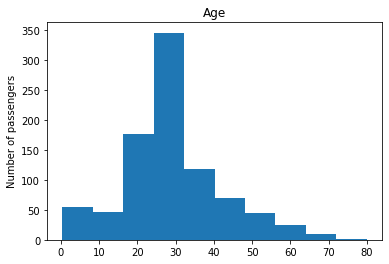

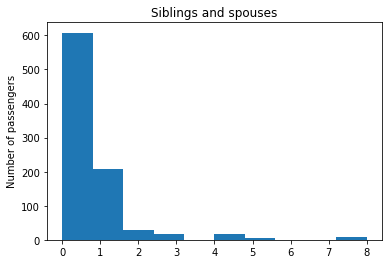

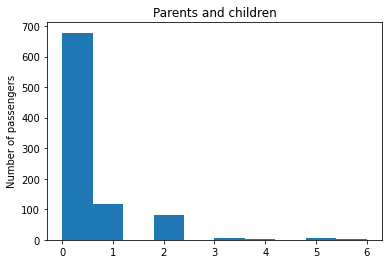

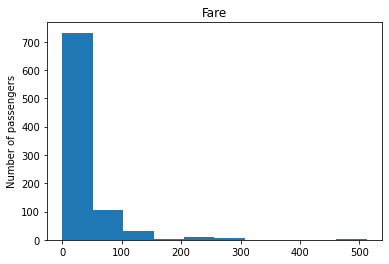

In [47]:
# Output: the same four histograms as before; the numeric columns have not changed.
# Draw histograms of the quantitative data
quanTrainingData = trainingData[['Age','SibSp','Parch','Fare']]
for iteration in quanTrainingData.columns:
    matplot.hist(quanTrainingData[iteration])
    if iteration == 'SibSp':
        title = 'Siblings and spouses'
    elif iteration == 'Parch':
        title = 'Parents and children'
    elif iteration == 'binnedSibsp':
        title = 'Binned Siblings and Spouses'
    else:
        title = iteration
    matplot.title(title)
    matplot.ylabel('Number of passengers')
    matplot.show()

### New feature: military age

`cat_military` is 1 for men aged 18 to 41 and 0 for everyone else. The check uses `military_ages_id.values`, because `in` on a pandas Series looks at the index (row numbers), not at the values.

⚠️ The first loop is meant to leave out the clergy, but it searches for *Reverend*, and the names only contain *Rev.*, so nobody is removed.

In [48]:
# Why: a 0/1 feature for men of 'military age' (18 to 41).
# Output: none. The clergy loop prints nothing, because the names contain 'Rev.', not 'Reverend'.
# Select those of military age
# Remove those who are clergy
clergy_array = ['Reverend']
to_check_array = []
# Iterate through the names and extract a title
i = 0
for item in trainingData['Title'].items():
    string = str(item)
    if any (title in string for title in clergy_array):
        i = (i + 1)
        to_check_array.append(i)
        print(i)
# Select all men
men_data = trainingData.loc[trainingData['Sex'] == 'male']
# Select those 18 or over
men_data_over_18 = men_data.loc[men_data['Age']>17]
# Remove those over 41
final_military_age_data = men_data_over_18.loc[men_data_over_18['Age']<42]
military_ages_id = final_military_age_data['PassengerId']
in_military_array = []

for item in trainingData['PassengerId']:
    if item in military_ages_id.values:  # .values: compare with the IDs themselves, not with the row labels
        in_military_array.append(1)
    else:
        in_military_array.append(0)
# Assign the categorical data to a new column
trainingData['cat_military'] = in_military_array

⚠️ `drop` returns a new table and leaves `trainingData` unchanged unless the result is stored (`trainingData = trainingData.drop(...)`). The output shows the table without `Cabin` only, because that is the last of the three calls; `Name`, `Ticket` and `Cabin` all remain in `trainingData`.

In [49]:
# Why: meant to remove columns that the analysis does not need.
# Output: the table without Cabin (only the last drop is shown); trainingData keeps all its columns (see the note above).
# Drop the unnecessary data - the names, tickets and cabins
# Backup the data
name_backup = trainingData['Name']
ticket_backup = trainingData['Ticket']
cabin_backup = trainingData['Cabin']
trainingData.drop('Name',axis=1)
trainingData.drop('Ticket',axis=1)
trainingData.drop('Cabin',axis=1)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,...,cat_Parch,cat_Ticket,cat_ticket,cat_fare,norm_SibSp,norm_Fare,Title,cat_title,cat_rich,cat_military
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.2500,...,Low,A/5 21171,letter,0-99,0.693147,2.110213,"Braund, Mr. Owen Harris",Mr.,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.2833,...,Low,PC 17599,letter,0-99,0.693147,4.280593,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Mrs.,1,0
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.9250,...,Low,STON/O2. 3101282,letter,0-99,0.000000,2.188856,"Heikkinen, Miss. Laina",Miss,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.1000,...,Low,113803,noLetter,0-99,0.693147,3.990834,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs.,1,0
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.0500,...,Low,373450,noLetter,0-99,0.000000,2.202765,"Allen, Mr. William Henry",Mr.,0,1
5,6,0,3,"Moran, Mr. James",male,29.699118,0,0,330877,8.4583,...,Low,330877,noLetter,0-99,0.000000,2.246893,"Moran, Mr. James",Mr.,0,1
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.000000,0,0,17463,51.8625,...,Low,17463,noLetter,0-99,0.000000,3.967694,"McCarthy, Mr. Timothy J",Mr.,1,0
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.000000,3,1,349909,21.0750,...,Low,349909,noLetter,0-99,1.386294,3.094446,"Palsson, Master. Gosta Leonard",Master,0,0
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.000000,0,2,347742,11.1333,...,Low,347742,noLetter,0-99,0.000000,2.495954,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",Mrs.,0,0
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.000000,1,0,237736,30.0708,...,Low,237736,noLetter,0-99,0.693147,3.436268,"Nasser, Mrs. Nicholas (Adele Achem)",Mrs.,0,0


## 3. Analysis

Every model below uses a single 0/1 feature (or a small group of them) to predict `Survived`, so you can compare how much each feature on its own tells us about survival.

In [50]:
# (Section marker only: this cell has no code and prints nothing.)
#----START OF ANALYSIS

### One-hot encoding

The models need numbers, so the age group becomes three 0/1 columns (`0-15`, `16-64`, `65+`) and sex becomes two (`cat_female`, `cat_male`). Despite their names, the age columns follow the bins from section 2: 0–14, 15–64 and over 64.

In [51]:
# Why: turn the age groups into three 0/1 columns, the format the models below need.
# What: each loop walks over the 891 rows and writes 1 if the passenger is in that group, else 0; passengers without an age group get 0 everywhere.
# Output: none (no 'Error at' lines, so every row was read).
# Note: despite the names, '0-15' holds ages 0-14 and '16-64' holds ages over 14 up to 64; pd.get_dummies() could do this in one line.
# Change the 'cat_age' into a format that works with the analysis algorithms ('one hot' encoding)
one_hot_array = []
i = 0
while i < 891:
    one_hot_array.append(0)
    i = (i + 1)
trainingData['0-15'] = one_hot_array
trainingData['16-64'] = one_hot_array
trainingData['65+'] = one_hot_array
iterator = 0
zero_fifteen_array = []
while iterator < 891:
    try:
        currentAge = trainingData['cat_age'].loc[iterator]
        if currentAge == 'Low':
            zero_fifteen_array.append(1)
            iterator = (iterator + 1)
        else:
            zero_fifteen_array.append(0)
            iterator = (iterator + 1)
    except:
        # If there are any errors, put 0 in as default
        zero_fifteen_array.append(0)
        print("Error at ",iterator)
        iterator = (iterator + 1)
trainingData['0-15'] = zero_fifteen_array

iterator = 0
sixteen_sixtyfour_array = []
while iterator < 891:
    try:
        currentAge = trainingData['cat_age'].loc[iterator]
        if currentAge == 'Middle':
            sixteen_sixtyfour_array.append(1)
            iterator = (iterator + 1)
        else:
            sixteen_sixtyfour_array.append(0)
            iterator = (iterator + 1)
    except:
        # If there are any errors, put 0 in as default
        sixteen_sixtyfour_array.append(0)
        #print("Error at ",iterator)
        iterator = (iterator + 1)
trainingData['16-64'] = sixteen_sixtyfour_array

iterator = 0
sixtyfive_array = []
while iterator < 891:
    try:
        currentAge = trainingData['cat_age'].loc[iterator]
        if currentAge == 'High':
            sixtyfive_array.append(1)
            iterator = (iterator + 1)
        else:
            sixtyfive_array.append(0)
            iterator = (iterator + 1)
    except:
        # If there are any errors, put 0 in as default
        sixtyfive_array.append(0)
        #print("Error at ",iterator)
        iterator = (iterator + 1)
trainingData['65+'] = sixtyfive_array

In [52]:
# Why: turn Sex into two 0/1 columns: cat_female (1 = woman) and cat_male (1 = man).
# Output: none.
# Note: the two columns are exact opposites, so a model gets the same information from either one.
# Change the 'sex' into a format that works with the analysis algorithms ('one hot' encoding)
b = 0
gender_array = []
while b < 891:
    currentGender = trainingData['Sex'].loc[b]
    try:
        if currentGender == 'male':
            gender_array.append(0)
            b = (b + 1)
        else:
            gender_array.append(1)
            b = (b + 1)
    except:
        # If there are any errors, put 0 in as default as we need to positively determine if the entry was female or not
        gender_array.append(0)
        b = (b + 1)
        print("Error in ",currentGender)
trainingData['cat_female'] = gender_array

b = 0
gender_array_2 = []
while b < 891:
    currentGender2 = trainingData['Sex'].loc[b]
    try:
        if currentGender2 == 'male':
            gender_array_2.append(1)
            b = (b + 1)
        else:
            gender_array_2.append(0)
            b = (b + 1)
    except:
        # If there are any errors, put 0 in as default as we need to positively determine if the entry was male or not
        gender_array_2.append(0)
        b = (b + 1)
        print("Error in ",currentGender2)
trainingData['cat_male'] = gender_array_2

### Logistic regression

Each cell splits the data into 75% training and 25% test passengers (`random_state=0`, so the split is the same every time), fits a logistic regression on one feature, and shows the **confusion matrix** as a heat map (rows: actual outcome, columns: predicted outcome) and the **accuracy** on the test set.

<details><summary>What do you notice?</summary>

Sex gives the highest accuracy (0.78). The models with the age groups and with `0-15` reach 0.63, hardly better than the 0.62 you get by predicting "did not survive" for every test passenger (62% of them died), so age group alone helps very little. `cat_rich` reaches 0.71 and `cat_military` reaches 0.69: men of military age mostly did not survive.
</details>

**What is logistic regression?** Despite its name, it is a *classification* method. It estimates the probability (between 0 and 1) that a passenger survived from the input columns, and predicts 1 (survived) when that probability is above 0.5. With a single 0/1 feature the model can give only one prediction per group, so its accuracy shows how much that one feature tells us about survival.

In [53]:
# (Section marker only: this cell has no code and prints nothing.)
# Complete a Simple Logistic Regression analysis

Accuracy:  0.6322869955156951


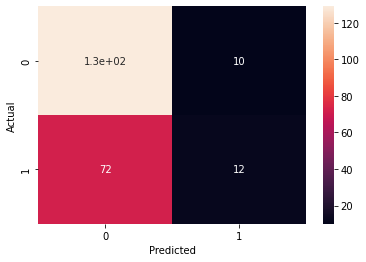

In [54]:
# Why: predict survival from the three age-group columns with logistic regression.
# What: train_test_split keeps 25% of the passengers aside for testing; random_state=0 gives the same split every time.
# Output: 'Accuracy: 0.632...' and a heat map of the confusion matrix (rows: actual, columns: predicted).
# Note: `logreg` is not used, and the name confusion_matrix now holds a table, hiding the scikit-learn function imported in the first cell.
# Age group (0-15, 16-64, 65+) to survival
logreg = LogisticRegression()
x = trainingData[['0-15','16-64','65+']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)  # annot=True writes the count in each square

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

Accuracy:  0.7802690582959642


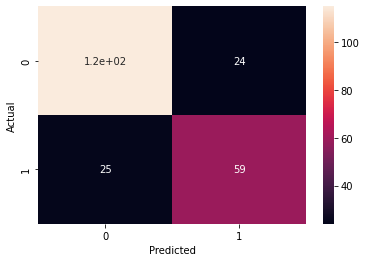

In [55]:
# Why: the same model with one feature, cat_female.
# Output: 'Accuracy: 0.780...', the best of the logistic regressions, and its confusion-matrix heat map.
# Being female to survival
logreg = LogisticRegression()
x = trainingData[['cat_female']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

Accuracy:  0.7802690582959642


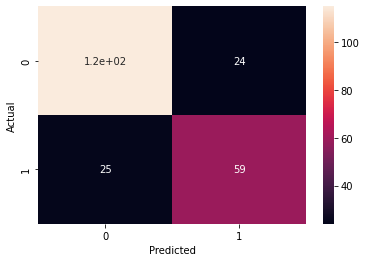

In [56]:
# Why: the same model with cat_male.
# Output: the same accuracy (0.780...) as cat_female, because cat_male is its exact opposite.
# Being male to survival
logreg = LogisticRegression()
x = trainingData[['cat_male']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

Accuracy:  0.6322869955156951


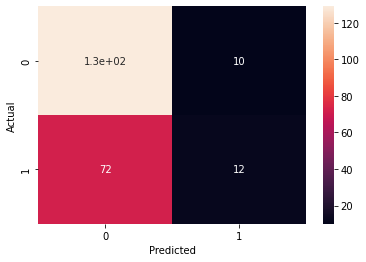

In [57]:
# Why: the same model with the youngest age group only.
# Output: 'Accuracy: 0.632...', the same as with all three age groups.
# Being in the youngest age group (0-14, column '0-15') to survival
logreg = LogisticRegression()
x = trainingData[['0-15']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

Accuracy:  0.7085201793721974


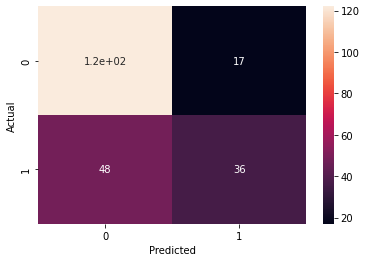

In [58]:
# Why: the same model with cat_rich (first class).
# Output: 'Accuracy: 0.708...'.
# Being rich to survival
logreg = LogisticRegression()
x = trainingData[['cat_rich']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

Accuracy:  0.6860986547085202


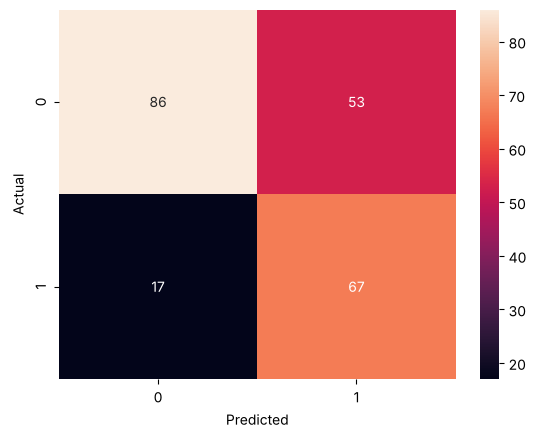

In [59]:
# Being of military age to survival
# Why: the same model with cat_military.
# Output: 'Accuracy: 0.686...'.
logreg = LogisticRegression()
x = trainingData[['cat_military']]
y = trainingData['Survived']
X_train,X_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=0)

logistic_regression= LogisticRegression()
logistic_regression.fit(X_train,y_train)
y_pred=logistic_regression.predict(X_test)

confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
seaborn.heatmap(confusion_matrix, annot=True)

print('Accuracy: ',metrics.accuracy_score(y_test, y_pred))
matplot.show()

### Association rules (Apriori)

Apriori looks for combinations of features that often occur together. These cells gather the 0/1 columns into one table, find all *itemsets* with `apriori`, and turn them into rules *A → B* with `association_rules`. For a rule:

- **support**: the share of passengers who have both A and B;
- **confidence**: among passengers with A, the share who also have B;
- **lift**: confidence divided by the share of passengers with B. A lift above 1 means A makes B more likely.

The very small `min_support` keeps every itemset that occurs at least once. The first cell combines the three age columns into one column, `cat_all_age` (1, 2 or 3), for the models further down.

In [60]:
# (Section marker only: this cell has no code and prints nothing.)
# # Complete an Apriori analysis

In [61]:
# Why: combine the three age columns into one column, cat_all_age:
# 1 = 0 to 14, 2 = over 14 up to 64, 3 = over 64, and 0 = age group unknown (missing age).
# Output: none. The gradient-boosting and random-forest models below use this column.
# Combine the age categories into one column
final_age_array = []
young_age_to_check = trainingData['0-15']
middle_age_to_check = trainingData['16-64']
older_age_to_check = trainingData['65+']
for item in young_age_to_check:
    if item == (1):
        final_age_array.append(1)
    else:
        final_age_array.append(0)
e = 0
for item in middle_age_to_check:
    if item == (1):
        final_age_array[e] = 2
        e = (e + 1)
    else:
        e = (e + 1)
e = 0
for item in older_age_to_check:
    if item == (1):
        final_age_array[e] = 3
        e = (e + 1)
    else:
        e = (e + 1)
# Set the data to a new column, 'cat_all_age'
trainingData['cat_all_age'] = final_age_array

In [62]:
# Why: collect the 0/1 features in one table, the input apriori needs: one column per item, one row per passenger.
# Output: the table, 891 rows x 8 columns, printed in full.
# Note: some names are misleading: 'under16' holds the 0-14 group, and over16_array holds the '16-64' column.
# Add all values from the categorical features to an array (to be added to the dataframe for the apriori algorithm)

to_check_survival = trainingData['Survived']
to_check_rich = trainingData['cat_rich']
to_check_under16 = trainingData['0-15']
to_check_16to64 = trainingData['16-64']
to_check_65plus = trainingData['65+']
to_check_female = trainingData['cat_female']
to_check_male = trainingData['cat_male']
to_check_mil = trainingData['cat_military']

survived_array = []
rich_array = []
under16_array = []
over16_array = []
over65_array = []
female_array = []
male_array = []
mil_array = []
dataframe_index = []
# Add all of the index values to the above array
d = 0
while d < 891:
    dataframe_index.append(d)
    d = (d+1)

# Add survival data
for item in to_check_survival:
    survived_array.append(item)
    
# Add rich data
for item in to_check_rich:
    rich_array.append(item)

# Add under 16 data
for item in to_check_under16:
    under16_array.append(item)

# Add female data
for item in to_check_female:
    female_array.append(item)

# Add male data
for item in to_check_male:
    male_array.append(item)

# Add age data
for item in to_check_16to64:
    over16_array.append(item)
for item in to_check_65plus:
    over65_array.append(item)
    
# Add military data
for item in to_check_mil:
    mil_array.append(item)

# Zip the data so it can be passed to the dataframe
to_add = list(zip(survived_array,rich_array,under16_array,female_array,male_array,over16_array,over65_array,mil_array))

aprioriTrainingData = pd.DataFrame(data = to_add,index=dataframe_index,columns=['Survived','is_rich','under16','female','male','16-64','65+','is_mil'] )
print(aprioriTrainingData)

     Survived  is_rich  under16  female  male  16-64  65+  is_mil
0           0        0        0       0     1      1    0       1
1           1        1        0       1     0      1    0       0
2           1        0        0       1     0      1    0       0
3           1        1        0       1     0      1    0       0
4           0        0        0       0     1      1    0       1
5           0        0        0       0     1      0    0       1
6           0        1        0       0     1      1    0       0
7           0        0        1       0     1      0    0       0
8           1        0        0       1     0      1    0       0
9           1        0        1       1     0      0    0       0
10          1        0        1       1     0      0    0       0
11          1        1        0       1     0      1    0       0
12          0        0        0       0     1      1    0       1
13          0        0        0       0     1      1    0       1
14        

In [63]:
# Why: find every combination of features (an itemset) and how often it occurs (its support).
# What: min_support=0.0000005 is below 1/891, so every combination that occurs at least once is kept; verbose=1 prints progress.
# Output: the progress lines and a table of 59 itemsets, e.g. Survived 0.38 (38% of the passengers survived).
# Note: the order of the names inside an itemset can change between runs; the numbers do not.
# Apply Apriori
frequent_items = apriori(aprioriTrainingData.astype(bool), min_support=0.0000005, use_colnames=True, verbose=1)  # 0/1 -> True/False, the type apriori expects
print(frequent_items)

Processing 5 combinations | Sampling itemset size 5
     support                                           itemsets
0   0.383838                              frozenset({Survived})
1   0.242424                               frozenset({is_rich})
2   0.086420                               frozenset({under16})
3   0.352413                                frozenset({female})
4   0.647587                                  frozenset({male})
5   0.702581                                 frozenset({16-64})
6   0.012346                                   frozenset({65+})
7   0.472503                                frozenset({is_mil})
8   0.152637                     frozenset({Survived, is_rich})
9   0.050505                     frozenset({under16, Survived})
10  0.261504                      frozenset({female, Survived})
11  0.122334                        frozenset({Survived, male})
12  0.273850                       frozenset({16-64, Survived})
13  0.001122                         frozenset({Surv

A bar chart of the support of the first ten itemsets (labels turned vertical so they can be read), then, in a separate figure, the distribution of all support values as a histogram with a smooth density curve (`histplot` with `kde=True`).

<Axes: xlabel='support', ylabel='Density'>

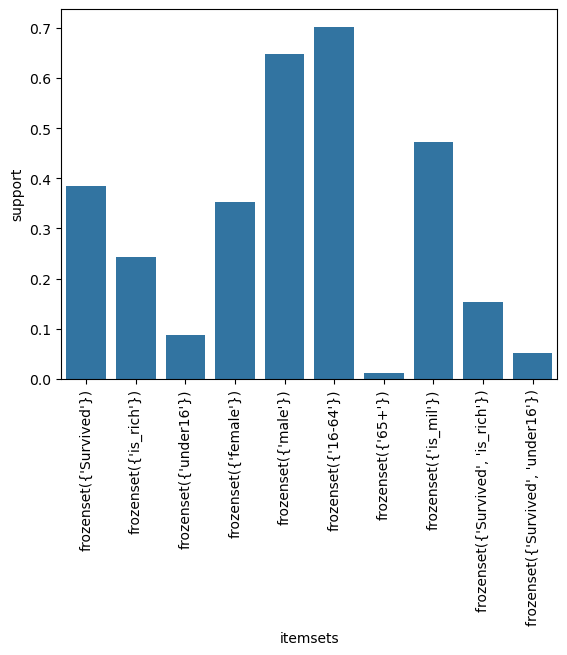

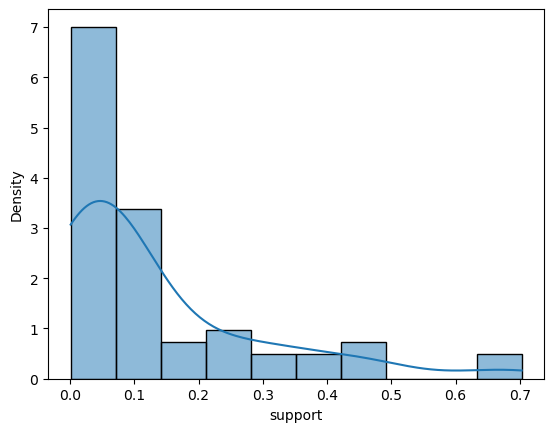

In [64]:
# Why: picture the support values from the previous cell.
# Output: two figures: the support of the first ten itemsets, and a histogram of all support values with a smooth curve.
# The <Axes ...> text above the figures can be ignored.
axis = seaborn.barplot(x='itemsets',y='support',data=frequent_items[:10])
matplot.xticks(rotation=90)  # vertical labels, so the itemset names do not overlap
matplot.figure()  # new figure, so the histogram is not drawn on top of the bar chart
seaborn.histplot(frequent_items['support'], kde=True, stat='density')

The rules, first filtered by confidence ≥ 0.5 and then by lift ≥ 0.5 (newer versions of `mlxtend` add extra measures such as `zhangs_metric` and `kulczynski` to the table). The next cells print the first 26 rules one by one and the full table sorted by consequent support.

In [65]:
# Why: turn the itemsets into rules A -> B and keep those with a confidence of at least 0.5.
# Output: a table of 80 rules, printed in several blocks because it is wide (antecedents, consequents, support, confidence, lift, ...).
# Try: raise min_threshold to 0.8 to keep only the strongest rules.
# Mine the association rules
rules = association_rules(frequent_items, metric="confidence", min_threshold=0.5)
print(rules)

                                      antecedents  \
0                            frozenset({is_rich})   
1                            frozenset({under16})   
2                             frozenset({female})   
3                           frozenset({Survived})   
4                           frozenset({Survived})   
5                            frozenset({is_rich})   
6                            frozenset({is_rich})   
7                                frozenset({65+})   
8                            frozenset({under16})   
9                             frozenset({female})   
10                             frozenset({16-64})   
11                              frozenset({male})   
12                               frozenset({65+})   
13                            frozenset({is_mil})   
14                              frozenset({male})   
15                            frozenset({is_mil})   
16                  frozenset({under16, is_rich})   
17                   frozenset({female, is_ric

In [66]:
# Why: the same rules filtered by lift of at least 0.5 instead, which keeps many more (258 rules).
# Output: the long table in several blocks. `rules` now holds this second set, which the next cells use.
rules = association_rules(frequent_items, metric="lift", min_threshold=0.5)
print(rules)

                                       antecedents  \
0                            frozenset({Survived})   
1                             frozenset({is_rich})   
2                             frozenset({under16})   
3                            frozenset({Survived})   
4                              frozenset({female})   
5                            frozenset({Survived})   
6                               frozenset({16-64})   
7                            frozenset({Survived})   
8                              frozenset({female})   
9                             frozenset({is_rich})   
10                            frozenset({is_rich})   
11                               frozenset({male})   
12                              frozenset({16-64})   
13                            frozenset({is_rich})   
14                            frozenset({is_rich})   
15                                frozenset({65+})   
16                            frozenset({is_rich})   
17                          

In [67]:
# Why: print the first 26 rules (rows 0 to 25) one by one.
# Output: 26 small one-row tables.
# Note: rules.loc[[n]] (double brackets) returns a one-row table instead of a single row (Series).
# Print the first 26 rows of the above table
rangeOfRows = 0
while rangeOfRows < 26:
    print(rules.loc[[rangeOfRows]])
    rangeOfRows = (rangeOfRows + 1)

             antecedents           consequents  antecedent support  \
0  frozenset({Survived})  frozenset({is_rich})            0.383838   

   consequent support   support  confidence      lift  representativity  \
0            0.242424  0.152637    0.397661  1.640351               1.0   

   leverage  conviction  zhangs_metric   jaccard  certainty  kulczynski  
0  0.059586    1.257723       0.633558  0.322275   0.204912    0.513645  
            antecedents            consequents  antecedent support  \
1  frozenset({is_rich})  frozenset({Survived})            0.242424   

   consequent support   support  confidence      lift  representativity  \
1            0.383838  0.152637     0.62963  1.640351               1.0   

   leverage  conviction  zhangs_metric   jaccard  certainty  kulczynski  
1  0.059586    1.663636       0.515294  0.322275   0.398907    0.513645  
            antecedents            consequents  antecedent support  \
2  frozenset({under16})  frozenset({Survived})    

In [68]:
# Why: sort all 258 rules from the smallest to the largest consequent support and print every row.
# Output: one very wide table; to_string() prints it without shortening, so scroll sideways to see all columns.
# Try: rules.sort_values(by='lift', ascending=False) shows the rules with the highest lift first.
# Sort the table by consequent support and print it
sorted_rules = rules.sort_values(by = 'consequent support')
print(sorted_rules.to_string())

                                       antecedents                                    consequents  antecedent support  consequent support   support  confidence      lift  representativity  leverage  conviction  zhangs_metric   jaccard  certainty  kulczynski
54                            frozenset({is_rich})                     frozenset({Survived, 65+})            0.242424            0.001122  0.001122    0.004630  4.125000               1.0  0.000850    1.003524       1.000000  0.004630   0.003511    0.502315
83                               frozenset({male})                     frozenset({Survived, 65+})            0.647587            0.001122  0.001122    0.001733  1.544194               1.0  0.000396    1.000612       1.000000  0.001733   0.000611    0.500867
183                           frozenset({is_rich})               frozenset({Survived, 65+, male})            0.242424            0.001122  0.001122    0.004630  4.125000               1.0  0.000850    1.003524       1.000000  

Scatter plots of the rules: support against confidence, lift against confidence, and support against lift.

<details><summary>Try it: find the rule "female → Survived"</summary>

Its confidence is about 0.74 (74% of women survived) and its lift about 1.93: being female almost doubles the chance of survival compared with the 38% survival rate of all passengers.
</details>

Text(0.5, 1.0, 'Support against confidence')

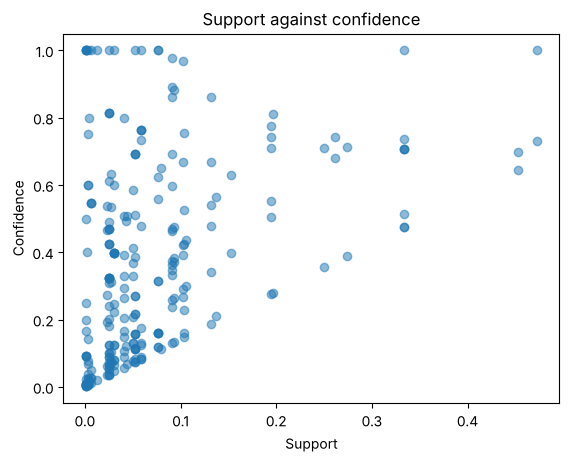

In [69]:
# Why: do rules with a high support also have a high confidence?
# Output: a scatter plot, one dot per rule. The Text(0.5, 1.0, ...) line is the return value of title() and can be ignored.
# Plot support vs confidence
matplot.scatter(rules['support'], rules['confidence'], alpha=0.5)
matplot.xlabel('Support')
matplot.ylabel('Confidence')
matplot.title('Support against confidence')

Text(0.5, 1.0, 'Lift against confidence')

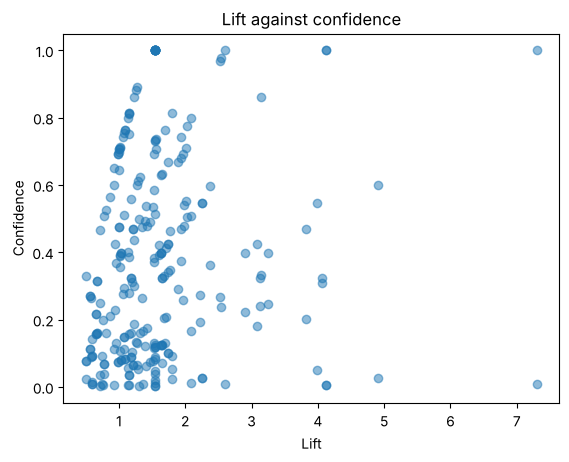

In [70]:
# Why: how lift and confidence relate across the rules.
# Output: a scatter plot, one dot per rule (again with a Text(...) line that can be ignored).
# Plot lift vs confidence
matplot.scatter(rules['lift'], rules['confidence'], alpha=0.5)
matplot.xlabel('Lift')
matplot.ylabel('Confidence')
matplot.title('Lift against confidence')

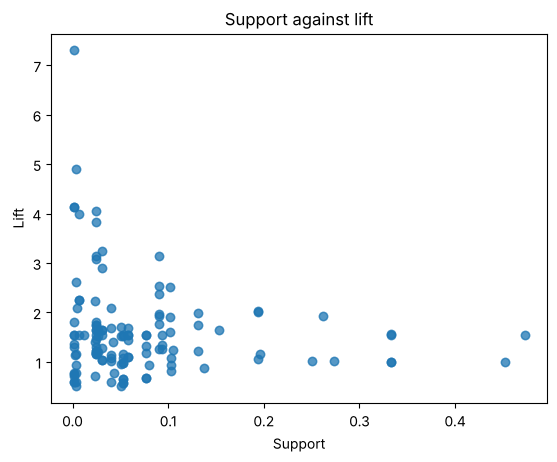

In [71]:
# Why: how support and lift relate across the rules.
# Output: a scatter plot; show() at the end means no Text(...) line this time.
# Plot support against lift
matplot.scatter(rules['support'], rules['lift'], alpha=0.5)
matplot.ylabel('Lift')
matplot.xlabel('Support')
matplot.title('Support against lift')
matplot.show()

### Gradient boosting

Gradient boosting builds many small decision trees, each correcting the errors of the previous ones. The original notebook used the CatBoost library, which cannot run in the browser; scikit-learn's `GradientBoostingClassifier` is used instead and gives exactly the same accuracies here, because with a single 0/1 feature any tree model can only predict the majority outcome of each group. These cells use a different split (`random_state=101`), so the numbers differ slightly from the logistic regression above.

In [72]:
# (Section marker only: this cell has no code and prints nothing.)
# Complete a gradient boosting analysis
# X = independent variable (feature)
# y = survival (dependent variable)

In [73]:
# Why: predict survival from cat_rich with gradient boosting.
# What: this split uses random_state=101, a different split from the logistic regression, so compare the accuracies with care.
# Output: the test accuracy, 0.668...
# Being rich to survival
X = trainingData[['cat_rich']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.6681614349775785

In [74]:
# Output: the test accuracy for cat_military, 0.681...
# Being military to survival
X = trainingData[['cat_military']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.6816143497757847

In [75]:
# Output: the test accuracy for the youngest age group, 0.600...
# Being in the youngest age group (0-14, column '0-15') to survival
X = trainingData[['0-15']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.600896860986547

In [76]:
# Output: the test accuracy for cat_all_age, 0.600..., no better than the youngest group alone.
# Age in general to survival
X = trainingData[['cat_all_age']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.600896860986547

In [77]:
# Output: the test accuracy for cat_female, 0.762..., the best gradient-boosting result.
# Being female to survival
X = trainingData[['cat_female']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.7623318385650224

In [78]:
# Output: the same accuracy as cat_female (0.762...), because cat_male is its exact opposite.
# Being male to survival
X = trainingData[['cat_male']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

gboost = GradientBoostingClassifier(random_state=0)
gboost.fit(X_train, y_train)
y_pred = gboost.predict(X_test)
accuracy_score(y_test, y_pred)

0.7623318385650224

### Random forest

A random forest trains 600 decision trees on random samples of the data and lets them vote. For each feature the notebook prints a **classification report** (precision, recall and F1 for each class) and the **confusion matrix** (rows: actual, columns: predicted).

<details><summary>What do you notice?</summary>

`cat_female` and `cat_male` give identical results, because one is the opposite of the other. `cat_military` reaches 0.68: the forest predicts "did not survive" for men of military age. For the age features the model predicts survival for very few passengers (recall 0.12 for class 1).
</details>

**How to read a classification report and a confusion matrix**

- **Precision** of a class: of the passengers *predicted* to be in that class, the share that really are.
- **Recall** of a class: of the passengers who really *are* in that class, the share the model finds.
- **F1-score**: one number that balances precision and recall (their harmonic mean).
- **Support**: the number of test passengers in each class (here 127 died and 96 survived).
- **Confusion matrix** `[[a b] [c d]]`: rows are the actual outcome (0, 1) and columns the prediction (0, 1), so `a` and `d` count the correct predictions.

In [79]:
# (Section marker only: this cell has no code and prints nothing.)
# Complete a random forest model

In [80]:
# Why: train a random forest that predicts survival from cat_female.
# Output: the model's description, RandomForestClassifier(n_estimators=600).
# Note: no random_state is set, but with a single 0/1 feature the predictions should not change between runs.
# On being female to survival
# Split the data into a training and testing split using an 75:25 ratio
X = trainingData[['cat_female']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [81]:
# Why: test the forest on the passengers it has not seen.
# Output: a classification report for class 0 (died) and 1 (survived), with an accuracy of 0.76 (see the markdown above).
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.76      0.86      0.80       127
           1       0.77      0.64      0.70        96

    accuracy                           0.76       223
   macro avg       0.76      0.75      0.75       223
weighted avg       0.76      0.76      0.76       223



In [82]:
# Output: the confusion matrix [[109 18] [35 61]]: rows are the actual outcome (0, 1), columns the prediction.
# 109 + 61 = 170 of the 223 test passengers are predicted correctly.
print(cm(y_test,prediction))

[[109  18]
 [ 35  61]]


In [83]:
# Why: the same forest with cat_male.
# Output: the model's description.
# On being male to survival
X = trainingData[['cat_male']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [84]:
# Output: the same report as for cat_female (accuracy 0.76), because cat_male is its exact opposite.
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.76      0.86      0.80       127
           1       0.77      0.64      0.70        96

    accuracy                           0.76       223
   macro avg       0.76      0.75      0.75       223
weighted avg       0.76      0.76      0.76       223



In [85]:
# Output: the same confusion matrix as for cat_female, [[109 18] [35 61]].
print(cm(y_test,prediction))

[[109  18]
 [ 35  61]]


In [86]:
# Why: the same forest with cat_military.
# Output: the model's description.
# On being of military age to survival
# Split the data into a training and testing split using an 75:25 ratio
X = trainingData[['cat_military']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [87]:
# Output: accuracy 0.68; it predicts 'survived' for everyone who is not a man of military age, so recall for class 1 is high (0.77).
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.78      0.61      0.69       127
           1       0.60      0.77      0.68        96

    accuracy                           0.68       223
   macro avg       0.69      0.69      0.68       223
weighted avg       0.70      0.68      0.68       223



In [88]:
# Output: [[78 49] [22 74]]: 78 + 74 = 152 of 223 correct.
print(cm(y_test,prediction))

[[78 49]
 [22 74]]


In [89]:
# Why: the same forest with cat_rich.
# Output: the model's description.
# On being rich to survival
# Split the data into a training and testing split using an 75:25 ratio
X = trainingData[['cat_rich']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [90]:
# Output: accuracy 0.67; recall for class 1 is only 0.43, because most survivors were not in first class.
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.66      0.85      0.74       127
           1       0.68      0.43      0.53        96

    accuracy                           0.67       223
   macro avg       0.67      0.64      0.64       223
weighted avg       0.67      0.67      0.65       223



In [91]:
# Output: [[108 19] [55 41]]: 108 + 41 = 149 of 223 correct.
print(cm(y_test,prediction))

[[108  19]
 [ 55  41]]


In [92]:
# Why: the same forest with the youngest age group.
# Output: the model's description.
# On being in the youngest age group (0-14, column '0-15') to survival
# Split the data into a training and testing split using an 75:25 ratio
X = trainingData[['0-15']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [93]:
# Output: accuracy 0.60; recall for class 1 is 0.12: the model predicts 'survived' for very few passengers.
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.59      0.96      0.73       127
           1       0.71      0.12      0.21        96

    accuracy                           0.60       223
   macro avg       0.65      0.54      0.47       223
weighted avg       0.64      0.60      0.51       223



In [94]:
# Output: [[122 5] [84 12]]: 122 + 12 = 134 of 223 correct.
print(cm(y_test,prediction))

[[122   5]
 [ 84  12]]


In [95]:
# Why: the same forest with cat_all_age.
# Output: the model's description.
# On age in general to survival
# Split the data into a training and testing split using an 75:25 ratio
X = trainingData[['cat_all_age']]
y = trainingData['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)
classifier = rfc(n_estimators=600)
classifier.fit(X_train,y_train)

RandomForestClassifier(n_estimators=600)

In [96]:
# Output: the same report as for the youngest group (accuracy 0.60).
prediction = classifier.predict(X_test)
print(cr(y_test, prediction))

              precision    recall  f1-score   support

           0       0.59      0.96      0.73       127
           1       0.71      0.12      0.21        96

    accuracy                           0.60       223
   macro avg       0.65      0.54      0.47       223
weighted avg       0.64      0.60      0.51       223



In [97]:
# Output: [[122 5] [84 12]], the same as for the youngest group.
print(cm(y_test,prediction))

[[122   5]
 [ 84  12]]


## Summary

- Missing data: `Cabin` is mostly missing, `Age` is missing for 177 passengers and was filled with the mean, `Embarked` for two.
- Age is related to sex, class and number of siblings/spouses on board.
- Of the single features tested, sex predicts survival best (about 76–78% accuracy), followed by first class (67–71%). Age group alone does little better than always predicting "did not survive". Being a man of military age (18–41) is also informative: about 68–69% accuracy.

<details><summary>Try it: improve the analysis</summary>

Fix one of the ⚠️ problems (for example, store the result of `drop`, or impute `Embarked` with the most frequent port), then train a model on several features together, such as `cat_female`, `cat_rich` and `0-15`. Does the accuracy improve on 0.78?
</details>